# SLR 3

This notebook analyzes the data extracted during the systematic literature review (SLR) and produces the figures used in the manuscript, as well as a supplementary "master coded table."

## Notebook structure

- **Imports** — loads all required packages.
- **Load Extracted Table** — loads and cleans `DataExtraction_Final.csv` (and cross-references it against the Zotero export) to build the working dataframe used throughout the notebook.
- **Plot Analysis** — generates all figures/distributions (see below).
- **Master Coded Table** — combines the final coded result from each subsection into a single per-paper table.
- **Build Crosstab Table** — cross-tabulates the study-design choices in `Master_Coded_Table.csv` against the validity verdict, saves `results/tables/Crosstab_Table_byVerdict.csv`, and plots the verdict by alignment level and relational alignment (`plot_verdictBy_Alignment_combined.pdf`).

## What's used in the manuscript?

The **Plot Analysis** section contains one subsection per figure/analysis. Not all of them are used in the manuscript — some are included purely for personal insight during the review process.

**Used in the manuscript** (all subsections under Plot Analysis except the two below):
- Distribution of Survey Datasets
- Distribution of Data Contamination
- Distribution of Survey Population
- Distribution of Predicted Variables
- Distributions of LLMs
- Persona-Construction Strategies
- Training Data & Training Specifications
- Distribution of Alignment Methods
- Distribution of Evaluation Strategies
- Validity of LLMs as Human Proxies

**Not used in the manuscript** (personal-insight only):
- Publication Type & Location
- Temporal Change

## Requirements
The notebook expects the extracted data files in `data/extraction/` (relative to the project root), most importantly `DataExtraction_Final.csv`.

# Imports

In [ ]:
# Standard Packages 
import numpy as np
import pandas as pd
import unicodedata
import time
import re
import os
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import textwrap

from matplotlib.path import Path
from pathlib import Path as FilePath
from matplotlib.patches import PathPatch
from dotenv import load_dotenv
from datetime import datetime
from typing import Dict, List, Optional, Iterable, Tuple
from difflib import SequenceMatcher
from collections import Counter
import regex
from collections import OrderedDict

import unicodedata

In [3]:
# Define path to the project folder
base = FilePath.cwd().parent

In [4]:
# Set a standard color for plots
sns.set_palette("viridis")

FIX_COLORS = [
    "#02A0E3",  # 1
    "#003d7c",  # 2
    "#006982",  # 3
    "#7c4b8c",  # 4
    "#66c1bd",  # 5
    "#d20064",  # 6
]
sns.set_palette(sns.color_palette(FIX_COLORS))
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=FIX_COLORS)

In [5]:
# Save figures as PDF (vector format — smaller files, publication-ready)
RESULTS_DIR = base / "results" / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def save_figure(filename):
    plt.savefig(RESULTS_DIR / f"{filename}.pdf", format="pdf", bbox_inches="tight")


# Load Extracted Table

In [6]:
# Define normalization function (normalize_title)
def normalize_title(s: str) -> str:
    # Unicode normalize
    s = unicodedata.normalize("NFKC", str(s))
    # Lowercase
    s = s.lower()
    # Remove punctuation-like characters
    s = re.sub(r"[^\w\s]", " ", s)   # keep letters, numbers, underscore, whitespace
    # Collapse whitespace
    s = re.sub(r"\s+", " ", s).strip()
    return s

In [7]:
# Load Data

# Load in DataExtraction Table
df_extraction_table_raw = pd.read_csv(base / "data/extraction/DataExtraction_Final.csv")

df_extraction_table = df_extraction_table_raw.drop(columns=['Venue', 'Citation count'])
df_extraction_table = df_extraction_table[df_extraction_table['Remove'] != 'Yes'].reset_index(drop=True) # Remove rows outside Inclusion Criteria
df_extraction_table['norm_title'] = df_extraction_table['Title'].apply(normalize_title)
print(f"Number of papers in the Data Extraction Table: {len(df_extraction_table)}")

# Load in Zotero Table (just for reference, not used in analysis)
df_extraction_table_zotero = pd.read_csv(base / "data/extraction/DataExtraction_Final_zotero.csv")
df_extraction_table_zotero['norm_title'] = df_extraction_table_zotero['Title'].apply(normalize_title)
df_extraction_table_zotero = df_extraction_table_zotero[['Title', 'norm_title', 'Publication Year', 'Author', 'DOI', 'Url', 'Item Type', 'Publication Title', 'Publisher', 'Conference Name']]

print(f"Number of papers in the Zotero Table: {len(df_extraction_table_zotero)}")

Number of papers in the Data Extraction Table: 55
Number of papers in the Zotero Table: 55


In [8]:
## Preprocess ##
# Survey Population
df_extraction_table["Survey Population"] = (df_extraction_table["Survey Population"]
                                            .astype("string").apply(normalize_title) )

# LLM Used
df_extraction_table["LLMs Used - Original"] = df_extraction_table["LLMs Used"].copy()
df_extraction_table["LLMs Used"] = (df_extraction_table["LLMs Used"]
                                    .astype("string").apply(normalize_title) )
# LLM Persona Adaptation Strategy
df_extraction_table["LLM Persona Adaptation Strategy"] = (df_extraction_table["LLM Persona Adaptation Strategy"]
                                                            .astype("string").apply(normalize_title) )

# LLM Training / Prompting Input
df_extraction_table["LLM Training / Prompting Input"] = (df_extraction_table["LLM Training / Prompting Input"]
                                                    .astype("string").apply(normalize_title) )

# Relational Alignment: 
df_extraction_table["Relational Alignment"] = df_extraction_table["Relational Alignment"].fillna("No").apply(lambda x: "Yes" if isinstance(x, str) and re.search(r"\brelational alignment\b", x, re.IGNORECASE) else ("No" if isinstance(x, str) and re.search(r"\bnone\b", x, re.IGNORECASE) else x))

###### Merge Metadata from Zotero ######
mapping_norm_titles = {
    "simulating human opinions with large language models": "simulating human opinions with large language models opportunities and challenges for personalized survey data modeling",
    "synthetic voices evaluating the fidelity of llm generated personas in representing people s financialwellbeing": "synthetic voices evaluating the fidelity of llm generated personas in representing people s financial wellbeing",
    "valuesim generating backstories to model individual value systems": "simvbg simulating individual values by backstory generation"
}

df_extraction_table['norm_title_mapped'] = df_extraction_table['norm_title'].map(mapping_norm_titles).fillna(df_extraction_table['norm_title'])

df_extraction_table = df_extraction_table.merge(
    df_extraction_table_zotero[['norm_title', 'Publication Year', 'Item Type', 'Publisher', 'Publication Title']].rename(columns={
        'norm_title': 'norm_title_mapped',
        'Publication Year': 'Publication Year',
        'Item Type': 'Item Type',
        'Publisher': 'Publisher',
        'Publication Title': 'Publication Title'
    }), left_on='norm_title_mapped', right_on='norm_title_mapped', how='left')
df_extraction_table['Year'] = (
    df_extraction_table['Publication Year']
    .fillna(df_extraction_table['Year'])
    .astype(int)
)
df_extraction_table = df_extraction_table.drop(columns=['norm_title_mapped', 'Publication Year'])

# Print number of papers in df_extraction_table
print(f'Number of papers in df_extraction_table: {len(df_extraction_table)}')
df_extraction_table.head(3)

Number of papers in df_extraction_table: 55


,Title,Authors,DOI,DOI link,Year,Survey Dataset,Survey Population,Application: Predicted variables,LLMs Used,LLM Persona Adaptation Strategy,...,Limitations,Data Contamination,Relational Alignment,"Reasoning for ""Relational Alignment""",Remove,norm_title,LLMs Used - Original,Item Type,Publisher,Publication Title
0,Adaptive political surveys and GPT-4: Tackling...,"Bachmann, Fynn, Weijden, Daan van der, Heitz, ...",10.1371/journal.pone.0322690,https://doi.org/10.1371/journal.pone.0322690,2025,"Smartvote, 2023 Swiss National Elections",swiss voters in the canton of zurich swiss pol...,75 Political questions from Smartvote of the 2...,model name gpt 4 nr version or release date nr,prompt engineering,...,- Synthetic data generated by GPT-4 is less ex...,A — Not addressed: No discussion of leakage/co...,No,- The paper primarily focuses on whether GPT-4...,No,adaptive political surveys and gpt 4 tackling ...,- Model name = GPT-4-NR; Version or release da...,journalArticle,Public Library of Science,PLOS ONE
1,AI-Human Hybrids for Marketing Research: Lever...,"Arora, N, Chakraborty, I, Nishimura, Y",10.1177/00222429241276529,https://doi.org/10.1177/00222429241276529,2025,Unique Questionnaires – Friendsgiving and refr...,us pet owners involved in pet food shopping,• Purchase likelihood: Measures how likely a r...,model name gpt 4 nr version or release date nr,prompt engineering,...,- Zero-shot prediction performance is limited ...,A — Not addressed: No discussion of leakage/co...,No,- The paper discusses how LLMs can generate sy...,No,ai human hybrids for marketing research levera...,- Model name = GPT-4-NR; Version or release da...,journalArticle,SAGE Publications Inc,Journal of Marketing
2,Algorithmic Fidelity of Large Language Models ...,"Bolei Ma, Berk Yoztyurk, Anna Haensch, Xinpeng...",10.48550/arXiv.2412.13169,https://doi.org/10.48550/arXiv.2412.13169,2025,German Longitudinal Election Studies (GLES) Wa...,german citizens eligible to vote during the re...,"Survey question: ""What is the most important p...",model name llama 2 13b chat hf version or rele...,prompt engineering,...,The limitations identified in the paper includ...,A — Not addressed: No discussion of leakage/co...,Yes,- The paper uses Cramér's V to measure the ass...,No,algorithmic fidelity of large language models ...,- Model name = Llama-2-13b-chat-hf; Version or...,conferencePaper,Association for Computational Linguistics,Proceedings of the 63rd Annual Meeting of the ...


# Plot Analysis


## Publication Type & Location

In [14]:
# Print type 
num_conference_papers_zotero = df_extraction_table[df_extraction_table['Item Type'] == 'conferencePaper'].shape[0]
num_journal_articles_zotero = df_extraction_table[df_extraction_table['Item Type'] == 'journalArticle'].shape[0]
total_papers_zotero = len(df_extraction_table)
print(f'Number of conference papers in Zotero: {num_conference_papers_zotero} ({(num_conference_papers_zotero / total_papers_zotero) * 100:.2f}%)')
print(f'Number of journal articles in Zotero: {num_journal_articles_zotero} ({(num_journal_articles_zotero / total_papers_zotero) * 100:.2f}%)')

Number of conference papers in Zotero: 31 (56.36%)
Number of journal articles in Zotero: 23 (41.82%)


In [15]:
# Journals
unique_publication_titles = df_extraction_table[df_extraction_table['Item Type'] == 'journalArticle']['Publication Title'].unique()
publication_title_counts = pd.DataFrame(unique_publication_titles, columns=['Publication Title'])
publication_title_counts['Count'] = publication_title_counts['Publication Title'].apply(lambda title: len(df_extraction_table[(df_extraction_table['Publication Title'] == title) & (df_extraction_table['Item Type'] == 'journalArticle')]))
publication_title_counts = publication_title_counts.sort_values(by='Count', ascending=False).reset_index(drop=True)

print(f'Total number of journal articles: {len(df_extraction_table[df_extraction_table['Item Type'] == 'journalArticle'])}')
publication_title_counts

Total number of journal articles: 23


,Publication Title,Count
0,Sociological Methods & Research,3
1,Political Analysis,2
2,Journal of Marketing,1
3,PLOS ONE,1
4,AoIR Selected Papers of Internet Research,1
5,Behavioral Science & Policy,1
6,PLOS Climate,1
7,International Journal of Selection and Assessment,1
8,Harvard Data Science Review,1
9,Proceedings of the International AAAI Conferen...,1


In [16]:
# Conference Proceedings
unique_publishers = df_extraction_table[df_extraction_table['Item Type'] == 'conferencePaper']['Publisher'].unique()
publisher_counts = pd.DataFrame(unique_publishers, columns=['Publisher'])
publisher_counts['Count'] = publisher_counts['Publisher'].apply(lambda publisher: len(df_extraction_table[(df_extraction_table['Publisher'] == publisher) & (df_extraction_table['Item Type'] == 'conferencePaper')]))
publisher_counts = publisher_counts.sort_values(by='Count', ascending=False).reset_index(drop=True)
print(f'Total number of conference papers: {len(df_extraction_table[df_extraction_table['Item Type'] == 'conferencePaper'])}')
publisher_counts

Total number of conference papers: 31


,Publisher,Count
0,Association for Computational Linguistics,17
1,Association for Computing Machinery,5
2,IEEE Computer Society,3
3,AHFE Open Access,1
4,AAAI Press,1
5,Springer Nature Switzerland,1
6,International Conference on Learning Represent...,1
7,JMLR.org,1
8,ELRA and ICCL,1


## Temporal Change

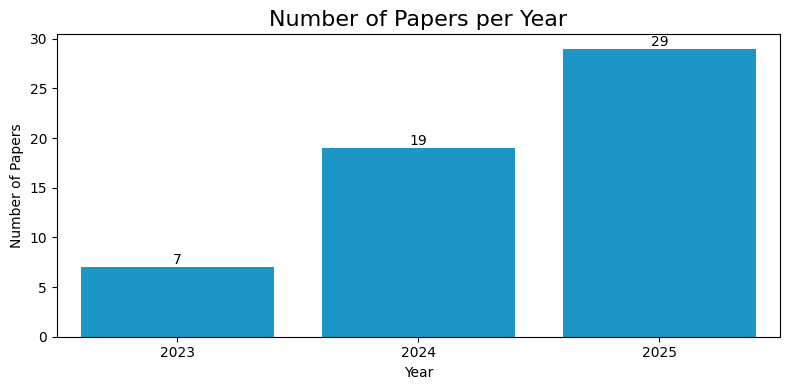

In [17]:
# Number of papers per year 
papers_per_year = df_extraction_table['Year'].value_counts().sort_index()

# plot bar chart of papers_per_year
plt.figure(figsize=(8, 4))
sns.barplot(x=papers_per_year.index, y=papers_per_year.values)
plt.xlabel('Year')
plt.ylabel('Number of Papers')
plt.title('Number of Papers per Year', fontsize=16)
# include count on top of bars
for index, value in enumerate(papers_per_year.values):
    plt.text(index, value, str(value), ha='center', va='bottom')
plt.tight_layout()
save_figure("Number_of_Papers_per_Year")
plt.show()

## Distribution of Survey Datasets

In [18]:
# Categorization framework
def categorize_survey_dataset(value):
    if pd.isna(value):
        return "Missing/Unknown"
    
    value_lower = str(value).lower()
    if "no survey dataset used" in value_lower:
        return "No Survey Dataset"
    
    if "prolific" in value_lower:
        return "Prolific custom questionnaires"
    
    if "world values survey" in value_lower or "wvs" in value_lower or "american national election" in value_lower or "anes" in value_lower or "pew" in value_lower or "american trends panel" in value_lower or "atp" in value_lower or "opinionqa" in value_lower or "german longitudinal election" in value_lower or "gles" in value_lower or "cooperative election study" in value_lower or "ces" in value_lower or "general social survey" in value_lower or "gss" in value_lower or "european social survey" in value_lower or "ess" in value_lower or "smartvote" in value_lower or "gfs.bern" in value_lower or "YouGov" in value_lower or "Cooperative Election Study" in value_lower:
        return "Established Surveys"
    
    if "unique questionnaires" in value_lower or "custom" in value_lower:
        return "Other questionnaires"
    
    return "Other questionnaires"

# Create a copy of the Data Extraction Table and select only the relevant columns for categorization
df_surveydataset = df_extraction_table[['Title', 'Authors', 'Survey Dataset']].copy()
df_surveydataset['Survey_Category'] = df_surveydataset['Survey Dataset'].apply(categorize_survey_dataset)

In [19]:
# Establish Surveys
df_established_surveys = df_surveydataset[df_surveydataset['Survey_Category'] == 'Established Surveys'].reset_index(drop=True)
df_established_surveys = df_established_surveys[['Survey Dataset', 'Survey_Category']]
survey_series = df_established_surveys['Survey Dataset'].dropna().astype(str).str.lower()

# Function to identify specific established surveys based on keywords
def identify_survey(text):
    text_lower = text.lower()
    if "world values survey" in text_lower or "wvs" in text_lower: 
        return "World Values Survey (WVS)"
    if "american national election" in text_lower or "anes" in text_lower:
        return "American National Election Studies (ANES)"
    if "pew" in text_lower or "american trends panel" in text_lower or "atp" in text_lower or "opinionqa" in text_lower:
        return "Pew Research Center Surveys"
    if "smartvote" in text_lower:   
        return "Smartvote"
    if "gfs.bern" in text_lower:
        return "Gfs Bern"
    if "ipsos" in text_lower:
        return "Ipsos"
    if "yougov" in text_lower:
        return "YouGov"
    if "german longitudinal election" in text_lower or "gles" in text_lower:
        return "German Longitudinal Election Studies (GLES)"
    if "cooperative election study" in text_lower or "ces" in text_lower:
        return "Cooperative Election Study (CES)"
    if "general social survey" in text_lower or "gss" in text_lower:
        return "General Social Survey (GSS)"
    if "european social survey" in text_lower or "ess" in text_lower:
        return "European Social Survey (ESS)"
    if "social media" in text_lower:
        return "Social Media Extracts"
    if "CES" in text_lower:
        return "Cooperative Election Study (CES)"
    return None

# Extract from all cells 
surveys = []
for text in survey_series:
    seen_in_row = set()
    parts = re.split(r'[;,|–\-]\s*', text)
    for part in parts:
        part = part.strip()
        if len(part) > 3:
            identified = identify_survey(part)
            if identified and identified not in seen_in_row:
                surveys.append(identified)
                seen_in_row.add(identified)

counts = Counter(surveys)
established_surveys_counts = pd.DataFrame.from_dict(counts, orient='index', columns=['count']).sort_values('count', ascending=False)


In [20]:
# Examples of the Other questionnaires
other_established_examples = df_surveydataset[df_surveydataset['Survey_Category'] == 'Other questionnaires']['Survey Dataset'].unique()
print("\nExamples of Other Surveys:")
for example in other_established_examples:
    print(f" - {example}")

# Examples of the custom Prolific questionnaires
custom_prolific_examples = df_surveydataset[df_surveydataset['Survey_Category'] == 'Prolific custom questionnaires']['Survey Dataset'].unique()
print("\nExamples of Prolific custom questionnaires:")
for example in custom_prolific_examples:
    print(f" - {example}")


Examples of Other Surveys:
 - Unique Questionnaires – Friendsgiving and refrigerated dog food concept studies conducted by a Fortune 500 food company in 2019.
 - Rothschild et al. (2019) human subject data
 - Unique Questionnaires – Controversial Beliefs Survey developed by Frigo (2022)
 - Unique Questionnaires – Custom-designed questions for environmental sustainability, financial literacy, and female participation in the labor force.
 - Unique Questionnaires – HEXACO-100 personality inventory and Balanced Inventory of Desirable Responding (BIDR)
 - Ipsos KnowledgePanel, October 2017 (N = 1,304) and September 2021 (N = 1,006)
 - - Leuven featurelisting norms (De Deyne et al., 2008)
- Unique Questionnaires – Semantic feature listing and verification, triadic similarity-matching, and Likert-scale pairwise similarity judgments conducted in 2022 and 2023
 - Kostka et al. (2021) Multinational Survey on Facial Recognition Technology
 - Unique Questionnaires – IPIP-50 questionnaire from the

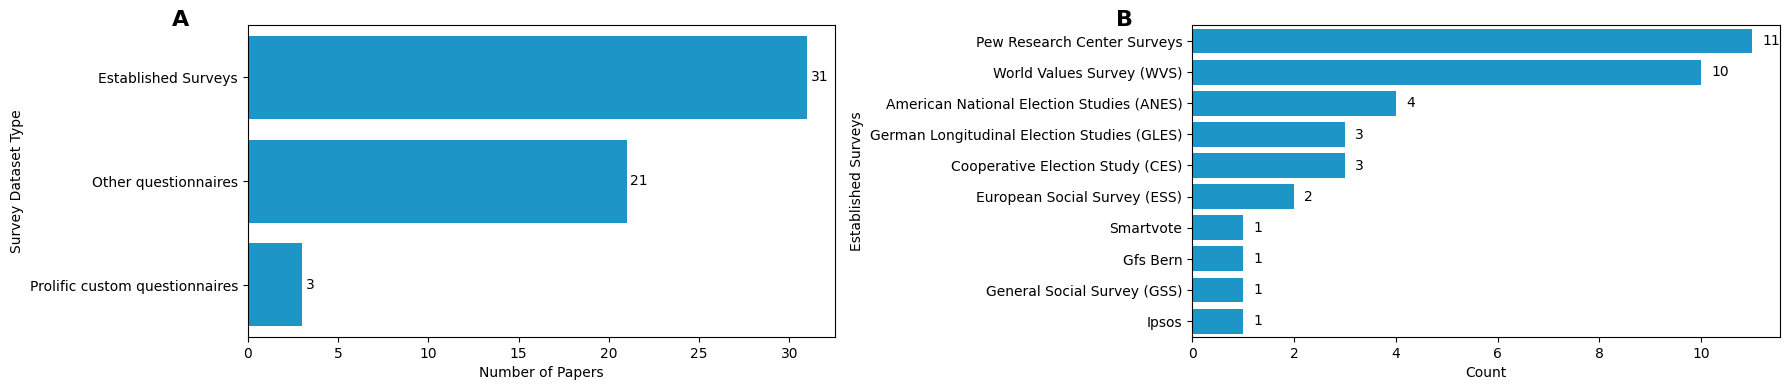

In [21]:
# Plot Distribution

fig, axes = plt.subplots(1, 2, figsize=(18, 4))

# First subplot: Distribution of Survey Dataset Categories
category_counts = df_surveydataset['Survey_Category'].value_counts()
sns.barplot(x=category_counts.values, y=category_counts.index, ax=axes[0])
axes[0].set_xlabel('Number of Papers')
axes[0].set_ylabel('Survey Dataset Type')
# axes[0].set_title('Distribution of Survey Dataset Type', fontsize=14)
axes[0].text(-0.1, 1.05, 'A', transform=axes[0].transAxes, fontsize=16, fontweight='bold', va='top', ha='right')
for i, v in enumerate(category_counts.values):
    axes[0].text(v + 0.2, i, str(v), color='black', va='center')

# Second subplot: Counts of Established Surveys
sns.barplot(x=established_surveys_counts['count'], y=established_surveys_counts.index, ax=axes[1])
axes[1].set_xlabel('Count')
axes[1].set_ylabel('Established Surveys')
# axes[1].set_title('Counts of Established Surveys', fontsize=14)
axes[1].text(-0.1, 1.05, 'B', transform=axes[1].transAxes, fontsize=16, fontweight='bold', va='top', ha='right')
for i, v in enumerate(established_surveys_counts['count']):
    axes[1].text(v + 0.2, i, str(v), color='black', va='center')

plt.tight_layout()
save_figure("Distribution_of_Survey_Dataset")
plt.show()

In [22]:
# # Print the Other questionnaires
# other_questionnaires = df_surveydataset[df_surveydataset['Survey_Category'] == 'Other questionnaires']['Survey Dataset'].dropna().unique()
# print("\nOther Questionnaires Used:")
# # Remove string of text: "Unique Questionnaires"
# other_questionnaires = [q.replace("Unique Questionnaires", "").strip() for q in other_questionnaires]
# for q in other_questionnaires:
#     print(q)

In [23]:
# # Print the Prolific Custom Questionnaires:
# print("\nProlific Custom Questionnaires Used:")
# prolific_questionnaires = df_surveydataset[df_surveydataset['Survey_Category'] == 'Prolific custom questionnaires']['Survey Dataset'].dropna().unique()
# # Remove string of text: "Prolific Custom Questionnaires"
# prolific_questionnaires = [q.replace("Prolific Custom Questionnaires", "").strip() for q in prolific_questionnaires]
# for q in prolific_questionnaires:
#     print(q)

# # what are the titles that used the Prolific Custom Questionnaires
# print("\nTitles Using Prolific Custom Questionnaires:")
# prolific_titles = df_surveydataset[df_surveydataset['Survey_Category'] == 'Prolific custom questionnaires']['Title'].dropna().unique()
# for title in prolific_titles:
#     print(title)

## Distribution of Data Contamination

In [24]:
# Clean 'Data Contamination' column
df_contamination = df_extraction_table[['Title', 'Authors', 'Data Contamination']].copy()
df_contamination['Contamination_Category'] = (
    df_contamination['Data Contamination'].str.strip()
    .apply(lambda x: (re.match(r'^([A-G])\b', x).group(1) if pd.notna(x) and re.match(r'^([A-G])\b', str(x)) else "Missing/Unknown"))
)

# Rename values A-G:
df_contamination['Contamination_Category'] = df_contamination['Contamination_Category'].replace({
    'A': 'A: Not addressed',
    'B': 'B: Acknowledged only (no mitigation step)',
    'C': 'C: Temporal exclusion (postdates training cutoff)',
    'D': 'D: Novel / Unpublished survey instrument',
})

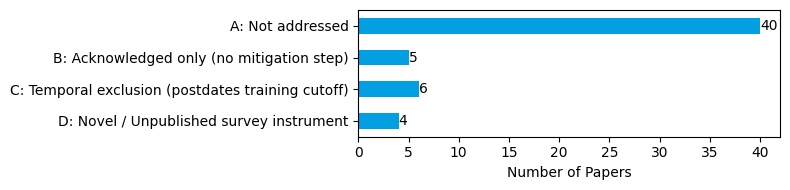

In [25]:
# Plot Horizontal Bar Chart
contamination_counts = df_contamination['Contamination_Category'].value_counts()
contamination_counts = contamination_counts.sort_index(ascending=False) # sort index

plt.figure(figsize=(8, 2))
contamination_counts.plot(kind='barh')
plt.xlabel('Number of Papers')
plt.ylabel('')
for index, value in enumerate(contamination_counts.values):
    plt.text(value, index, str(value), va='center')
plt.tight_layout()
save_figure("Distribution_of_Contamination_Categories")
plt.show()

## Distribution of Survey Population

In [26]:
# Define population keywords pattern
patterns_Population = {
    "United States": re.compile(r'\b(united states|u\.s\.|u\.s|us|usa|american|americans)\b', re.IGNORECASE),
    "Germany": re.compile(r'\b(germany|german)\b', re.IGNORECASE),
    "China": re.compile(r'\b(china|chinese|weibo|beijing)\b', re.IGNORECASE),
    "United Kingdom": re.compile(r'\b(united kingdom| uk |british)\b', re.IGNORECASE),
    "Japan": re.compile(r'\b(japan|japanese)\b', re.IGNORECASE),
    "Korea": re.compile(r'\b(south korea|korean| korea )\b', re.IGNORECASE),
    "Switzerland": re.compile(r'\b(switzerland|swiss|zurich)\b', re.IGNORECASE),
    "Norway": re.compile(r'\b(norway|norwegian)\b', re.IGNORECASE),
    "Spain": re.compile(r'\b(spain|spanish)\b', re.IGNORECASE),
    "Chile": re.compile(r'\b(chile|chilean)\b', re.IGNORECASE),
    "Russia": re.compile(r'\b(russia|russian|moscow)\b', re.IGNORECASE),
    "Australia": re.compile(r'\b(australia|australian|australians)\b', re.IGNORECASE),
    "Saudi Arabia": re.compile(r'\b(saudi arabia)\b', re.IGNORECASE),
    "United Arab Emirates": re.compile(r'\b(united arab emirates| uae )\b', re.IGNORECASE),
    "Canada": re.compile(r'\b(canada|canadian)\b', re.IGNORECASE),
    "Belgium": re.compile(r'\b(belgium|belgian)\b', re.IGNORECASE),
    "Egypt": re.compile(r'\b(egypt|egyptian)\b', re.IGNORECASE),
    "Mexico": re.compile(r'\b(mexico|mexican)\b', re.IGNORECASE),
    "South Africa": re.compile(r'\b(south africa|south african|south africans)\b', re.IGNORECASE),
    "Singapore": re.compile(r'\b(singapore|singaporean|singaporeans)\b', re.IGNORECASE),
    "Brazil": re.compile(r'\b(brazil|brazilian|brazilians)\b', re.IGNORECASE),
    "Sweden": re.compile(r'\b(sweden|swedish|swedes)\b', re.IGNORECASE),
    "Not Specified/Global": re.compile(r'\b(not specified|global|unspecified|unknown|not reported)\b', re.IGNORECASE)
}

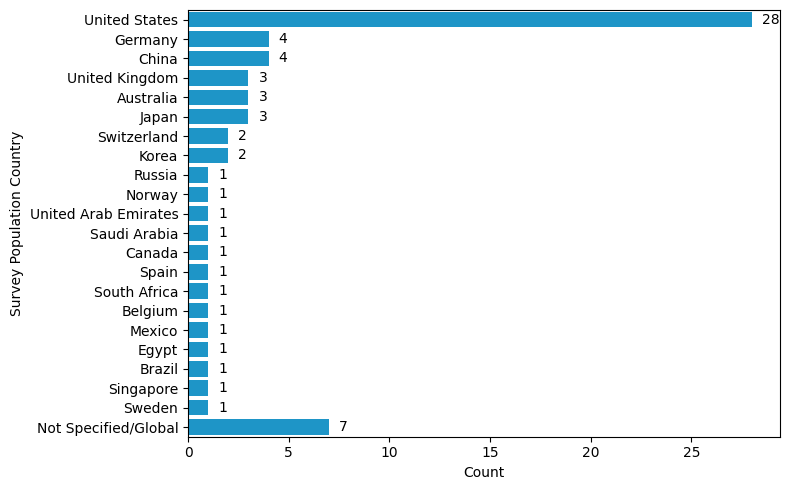

In [27]:
# Run Exraction and Categorization of Survey Population

# Create table with binary indicators
df_population = df_extraction_table[['Title', 'Survey Population']].copy()
for country, pattern in patterns_Population.items():
    df_population[country] = df_population['Survey Population'].apply(lambda x: 1 if pattern.search(str(x)) else 0)

# Count the number of papers for each country
country_counts = df_population.drop(columns=['Title', 'Survey Population']).sum().sort_values(ascending=False)
country_counts_df = country_counts.reset_index()
country_counts_df.columns = ['Country', 'Count']
country_counts_df = pd.concat([country_counts_df[country_counts_df['Country'] != 'Not Specified/Global'],
                                country_counts_df[country_counts_df['Country'] == 'Not Specified/Global']]).reset_index(drop=True)
country_counts_df = country_counts_df[country_counts_df['Count'] > 0].reset_index(drop=True)

# Plot the distribution of countries
plt.figure(figsize=(8, 5))
sns.barplot(x='Count', y='Country', data=country_counts_df)
plt.xlabel('Count')
plt.ylabel('Survey Population Country')
# plt.title('Distribution of Survey Populations by Country', fontsize=16)
for index, value in enumerate(country_counts_df['Count']):
    plt.text(value + 0.5, index, str(value), color='black', va='center')
plt.tight_layout()
save_figure("Distribution_of_Survey_Populations")
plt.show()

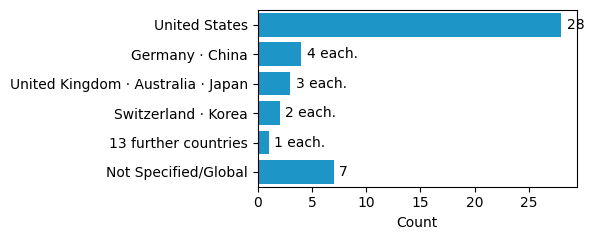

In [28]:
# Keep "Not Specified/Global" separate so it still lands at the bottom
not_specified = country_counts.get('Not Specified/Global', 0)
country_counts = country_counts[country_counts.index != 'Not Specified/Global']
country_counts = country_counts[country_counts > 0].sort_values(ascending=False)

# Group countries that share the same count
groups = OrderedDict()
for country, count in country_counts.items():
    groups.setdefault(count, []).append(country)

rows = []
for count, countries in sorted(groups.items(), key=lambda x: -x[0]):
    if count == 1 and len(countries) > 1:
        rows.append((f"{len(countries)} further countries", count, len(countries)))
    else:
        rows.append((" · ".join(countries), count, len(countries)))

# Add "Not Specified/Global" back at the very bottom, as before
if not_specified > 0:
    rows.append(('Not Specified/Global', not_specified, 1))

country_counts_df = pd.DataFrame(rows, columns=['Country', 'Count', 'N'])

# Plot — same style as original
plt.figure(figsize=(6, 2.5))
sns.barplot(x='Count', y='Country', data=country_counts_df)
plt.xlabel('Count')
plt.ylabel('')
plt.title('')
for index, row in country_counts_df.iterrows():
    label = f"{row['Count']} each." if row['N'] > 1 else str(row['Count'])
    plt.text(row['Count'] + 0.5, index, label, color='black', va='center')
plt.tight_layout()
save_figure("Distribution_of_Survey_Populations_simplified")
plt.show()

In [29]:
# Extra Insights
df_population['Multiple Countries (US + Others)'] = df_population.apply(lambda row: 1 if row['United States'] == 1 and row.drop(['Title', 'Survey Population', 'United States']).sum() > 0 else 0, axis=1)
df_population['Multiple Countries (Others)'] = df_population.apply(lambda row: 1 if row['United States'] == 0 and row.drop(['Title', 'Survey Population', 'United States']).sum() > 1 else 0, axis=1)

# Count papers that include US + other countries, and papers that include multiple countries excluding US
num_us_plus_others = df_population['Multiple Countries (US + Others)'].sum()
num_others_multiple = df_population['Multiple Countries (Others)'].sum()
print(f'Number of papers that include US + other countries: {num_us_plus_others}')
print(f'Number of papers that include multiple countries excluding US: {num_others_multiple}')

num_only_us = df_population[(df_population['United States'] == 1) & (df_population.drop(columns=['Title', 'Survey Population', 'United States']).sum(axis=1) == 0)].shape[0]
num_only_one_other = df_population[(df_population['United States'] == 0) & (df_population.drop(columns=['Title', 'Survey Population', 'United States']).sum(axis=1) == 1)].shape[0]
print(f'Number of papers that only use US population: {num_only_us}')
print(f'Number of papers that only use one other country population (excluding US): {num_only_one_other}')

Number of papers that include US + other countries: 10
Number of papers that include multiple countries excluding US: 0
Number of papers that only use US population: 18
Number of papers that only use one other country population (excluding US): 19


## Distribution of Predicted Variables

In [30]:
# Define coding rules 
patterns_VariablesPredicted = {
    "Political Attitudes, Values and Behaviors": [
        r"\bpolitic", r"\bpolicy", r"\bpublic opinion", r"\bopinion poll",
        r"\belection", r"\bvot(e|ing)\b", r"\bcongress\b", r"\bgovernment\b",
        r"\bpresident\b", r"\bprime minister\b", r"\bparty\b", r"\bpartisan\b",
        r"\bideolog", r"\bsupreme court\b", r"\bpolitical attitudes?\b",
        r"\bpolitical engagement\b", r"\bdirect democracy\b",
        r"\bnational interests?\b", r"\bmilitary\b", r"\bterritorial integrity\b",
        r"\bsmartvote\b", r"\bboric\b", r"\bbiden\b", r"\bnavalny\b",
        r"\bputin\b", r"\bmost important problem\b", r"\bpolitical system\b",
        r"\bvote choice\b", r"\bvoting decision\b", r"\bapproval\b",
        r"\bsupport\b", r"\boppose\b"
    ],
    
    "Psychological Traits": [
        r"\bpersonality\b", r"\bbig five\b", r"\bhexaco\b", r"\bextraversion\b",
        r"\bagreeableness\b", r"\bconscientiousness\b", r"\bopenness\b",
        r"\bneuroticism\b", r"\bhonesty-humility\b", r"\bemotionality\b",
        r"\bpsychoticism\b", r"\blie scale\b", r"\beysenck\b",
        r"\bsocial desirability\b", r"\bbidr\b", r"\bprestige\b",
        r"\boccupation\b", r"\bfeature listing\b", r"\bsimilarity\b",
        r"\bsemantic\b", r"\bjudg(e|ment)\b"
    ],

    "Social Attitudes, Values and Trust": [
        r"\bsocial group", r"\bperceptions? of social groups\b", r"\battitude\b",
        r"\bfeeling thermometer\b", r"\btrust\b", r"\bconfidence\b",
        r"\bsocial trust\b", r"\bfriends?\b", r"\bindividual opinions\b",
        r"\bneighbors?\b", r"\bdifferent religion\b", r"\bdifferent nationality\b",
        r"\bdifferent race\b", r"\breligio", r"\brace\b", r"\bethnic\b",
        r"\bgender\b", r"\bsex\b", r"\bsocial class\b", r"\bcultural value",
        r"\bvalues?\b", r"\bmoral norms?\b", r"\bmoral judgment\b",
        r"\bfreedom\b", r"\bequality\b", r"\bsecurity\b", r"\bcultural diversity\b",
        r"\bworld values\b", r"\bvalue orientations?\b", r"\bmoral-religious\b",
        r"\bcore value\b", r"\btrust\b", r"\bconfidence\b", 
        r"\bgun regulation\b", r"\babortion\b", r"\bdeath penalty\b",
        r"\benvironment\b", r"\bclimate\b", r"\bglobal warming\b",
        r"\bclimate change\b", r"\bsustainab",
        r"privacy(?:\s+(?:concern|attitude|behavior|intention|risk|surveillance))?|\bsurveillance\b",
        r"(?:general|public|private)\s+acceptance\b",
        r"\bnation perception scores\b",
    ],

    "Economic Preferences": [
        r"\beconomic(?:s| topics)?\b|\beconomy\b",
        r"\bincome distribution\b",
        r"\blabor policy questions\b", r"\bminimum wage\b", 
        r"\bfraud risk\b",
        r"\bfinancial wellbeing\b", r"\bpersonal financial situation\b", 
        r"\bpoverty\b", r"\bwealth\b", r"\btax\b",
        r"\bstate of the economy\b", 
        r"\bcountry's current economic situation\b",
    ],

    "Consumer Preferences": [
        r"\bpurchase\b", r"\bbuy\b", r"\bbrand\b", r"\bproduct\b",
        r"\bconcept liking\b", r"\bconcept uniqueness\b", r"\bpurchase likelihood\b",
        r"\bfrequency of purchase\b", r"\bwillingness[- ]to[- ]pay\b", r"\bwtp\b",
        r"\blikelihood to recommend\b", r"\bbrand awareness\b",
        r"\bbrand consideration\b", r"\bcustomer\b", r"\bmarket research\b",
        r"\bonline game spending\b", r"\bfinancial products\b", r"\bdog food\b",
        r"\bsus\b", r"\blearnability\b", r"\busability\b"
    ],

    "Healthcare & Well-Being": [
        r"\bmedical\b", r"\bvaccin", r"\bcovid\b", r"\bphq-9\b",
        r"\bgad-7\b", r"\bdepression\b", r"\banxiety\b", r"\bstress\b",
        r"\bloneliness\b", r"\bflourishing\b", r"\bhappiness\b",
        r"\bwellbeing\b", r"\bwell-being\b", r"\bdiagnos", r"\bopioid\b",
        r"\bnhs\b", r"\bfood\b", r"\borganic\b", r"\bgm food\b",
        r"\bartificial preservatives\b", r"\bartificial coloring\b", r"\bhealth risk\b"
        r"\bnational health service\b"
    ],

    "Technology Usage & Capabilities": [
        r"\btechnology usage\b", 
        r"\bjava\b", r"\bsoftware engineering\b", r"\bprogramming\b",
    ],

    "Not Specified/Other": [
        r"\bnot specified\b", r"\bunspecified\b" 
    ]
}

In [31]:
# Run Extraction 

# Create binary columns
df_variables = df_extraction_table[['Title', 'Application: Predicted variables']].copy()

for category, patterns in patterns_VariablesPredicted.items():
    combined_pattern = re.compile("|".join(patterns), re.IGNORECASE)
    df_variables[category] = df_variables['Application: Predicted variables'].apply(lambda x: 1 if combined_pattern.search(str(x)) else 0)

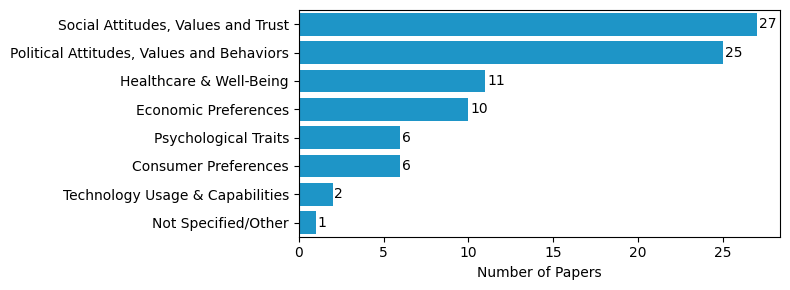

In [32]:
# Count
category_counts = df_variables.drop(columns=['Title', 'Application: Predicted variables']).sum().sort_values(ascending=False)
category_counts_df = category_counts.reset_index()
category_counts_df.columns = ['Variable Category', 'Count']
category_counts_df

# Plot
plt.figure(figsize=(8, 3))
sns.barplot(x='Count', y='Variable Category', data=category_counts_df)
plt.xlabel('Number of Papers')
plt.ylabel('')
# plt.title('Type of Variables Predicted')
for i, v in enumerate(category_counts_df['Count']):
    plt.text(v + 0.1, i, str(v), color='black', va='center')
plt.tight_layout()
save_figure("Distribution_of_Predicted_Variables")
plt.show()

## Distributions of LLMs

### Model Family

In [33]:
# Define models coding rules 
model_rules = {
    "OpenAI GPT Family": [
        r'\bchatgpt\b',
        r'\bgpt[\s-]?(?:2|3|3\.5|4|4o|4\.1|4\.5)\b',
        r'\bgpt[\s-]?(?:3\.5|4|4o|4\.1|4\.5)[\s-]?(?:turbo|mini|nano|preview|instruct)?\b',
        r'\bgpt[\s-]?\d+(?:\.\d+)?(?:[\s-]?(?:turbo|mini|nano|preview|instruct))?(?:-\d{4}-\d{2}-\d{2})?\b',
        r'\bo[13](?:[\s-]?mini)?\b',
        r'\btext-davinci-\d+\b',
        r'\bdavinci(?:-\d+)?\b',
        r'\btext-embedding-ada-\d+\b',
        r'\bada(?:-\d+[mb]?)?\b',
        r'\bbabbage(?:-\d+)?\b',
        r'\bcurie\b'
    ],

    "Claude / Anthropic Family": [
        r'\bclaude\b',
        r'\bclaude[\s-]?(?:1|2|3|3\.5)?(?:[\s-]?(?:haiku|sonnet|opus))?\b',
        r'\banthropic\b',
        r'\banthropic[\s-]?(?:haiku|sonnet|opus)\b'
    ],

    "Llama Family": [
        r'\bllama\b',
        r'\bllama[\s-]?(?:2|3|3\.1|3\.3|4)\b',
        r'\bllama[\s-]?(?:short|long)\b',
        r'\bllama[\s-]?\d+(?:\.\d+)?[\s-]?(?:\d+b|maverick|scout|chat|instruct|base|chinese|japanese)?(?:-\d+)?\b',
        r'\bdolphin[\s-]?llama(?:[\s-]?\d+(?:\.\d+)?)?\b',
        r'\bvillama\b'
    ],

    "Mistral Family": [
        r'\bmistral\b',
        r'\bmistral[\s-]?(?:small|large|large 2|7b|8x7b|8x22b)?(?:[\s-]?instruct)?(?:-v?\d+(?:\.\d+)*)?\b',
        r'\bmixtral\b',
        r'\bmixtral[\s-]?\d+x\d+b(?:[\s-]?instruct)?(?:-v?\d+(?:\.\d+)*)?\b',
        r'\bdolphin[\s-]?(?:\d+(?:\.\d+)?[\s-]?)?mistral\b'
    ],

    "Google Family": [
        r'\bgemma\b',
        r'\bgemma[\s-]?(?:2|3)?[\s-]?(?:2b|7b|9b|12b|27b)?(?:[\s-]?it|[\s-]?instruct)?\b',
        r'\bgemini\b',
        r'\bgemini[\s-]?(?:1\.0|1\.5)?[\s-]?(?:pro|flash)?\b',
        r'\bgemini[\s-]?(?:pro|flash)[\s-]?(?:1\.5|1\.0)?\b',
        r'\bflan[\s-]?(?:t5|u2|xl|xxl)\b',
        r'\bt5\b'
    ],

    "Qwen Family": [
        r'\bqwen\b',
        r'\bqwen[\s-]?(?:2|2\.5)?[\s-]?(?:7b|14b|32b|72b)?(?:[\s-]?coder)?\b',
        r'\bdistil[\s-]?qwen[\s-]?(?:7b|14b|32b)?\b'
    ],

    "ChatGLM Family": [
        r'\bchatglm\b',
        r'\bchatglm[\s-]?(?:2|3|4|4air)?(?:[\s-]?6b)?\b',
        r'\bglm[\s-]?(?:2|3|4|4air)\b'
    ],

    "Baichuan Family": [
        r'\bbaichuan\b',
        r'\bbaichuan[\s-]?2?(?:[\s-]?13b)?(?:[\s-]?chat)?\b'
    ],

    "WizardLM Family": [
        r'\bwizardlm\b',
        r'\bwizardlm[\s-]?(?:13b)?\b'
    ],

    "Falcon Family": [
        r'\bfalcon\b',
        r'\bfalcon[\s-]?(?:40b)?(?:[\s-]?instruct)?\b'
    ],

    "DeepSeek Family": [
        r'\bdeepseek\b',
        r'\bdeepseek[\s-]?(?:v3|r1)\b',
        r'\bdeepseek[\s-]?r1[\s-]?distill[\s-]?qwen[\s-]?(?:7b|14b|32b)?\b',
        r'\bdistill[\s-]?qwen[\s-]?(?:7b|14b|32b)?\b'
    ],

    "OLMo Family": [
        r'\bolmo\b',
        r'\bolmo[\s-]?2?(?:[\s-]?\d+)?(?:[\s-]?13b)?(?:[\s-]?(?:sft|dpo|instruct))?\b'
    ],

    "Phi Family": [
        r'\bphi\b',
        r'\bphi[\s-]?(?:3)?\b'
    ],

    "Cohere Command Family": [
        r'\bcommand[\s-]?r(?:[\s-]?plus)?\b',
        r'\bcohere\b'
    ],

    "AI21 Jurassic Family": [
        r'\bjurassic\b',
        r'\bj1[\s-]?(?:grande|jumbo)(?:[\s-]?v2)?(?:[\s-]?beta)?\b'
    ],

    "Doubao Family": [
        r'\bdoubao\b',
        r'\bdoubao[\s-]?1\.?5(?:[\s-]?pro)?\b'
    ],

    "Vicuna Family": [
        r'\bvicuna\b',
        r'\bvicuna[\s-]?1\.?5(?:[\s-]?(?:7b|13b))?\b'
    ],

    "Alpaca Family": [
        r'\balpaca\b',
        r'\balpaca[\s-]?7b\b'
    ],

    "MT0 / mT0 Family": [
        r'\bmt0\b',
        r'\bmt0[\s-]?xxl(?:[\s-]?13b)?\b'
    ],

    "AceGPT Family": [
        r'\bacegpt\b',
        r'\bacegpt[\s-]?13b(?:[\s-]?chat)?\b'
    ]
}

In [34]:
# Run extraction into a Table with binary columns
df_models = df_extraction_table[['Title', 'Year', 'LLMs Used']].copy()

model_families = model_rules.keys()
for family in model_families:
    keywords = model_rules[family]
    df_models[family] = df_models['LLMs Used'].apply(
        lambda x: int(any(re.search(keyword, str(x).lower()) for keyword in keywords))
    )

# Create a summary count
model_family_counts = (
    df_models[model_families]
    .sum()
    .to_frame('Count')
    .reset_index(names=['Model Family'])
    .sort_values('Count', ascending=False)
    .reset_index(drop=True)
)
model_family_counts = model_family_counts[model_family_counts['Count'] > 0].reset_index(drop=True)

# Plot the distribution of model families
# plt.figure(figsize=(8, 6))
# sns.barplot(x='Count', y='Model Family', data=model_family_counts)
# plt.xlabel('Number of Papers')
# plt.ylabel('Model Family')
# plt.title('Distribution of LLM Model Families Used', fontsize=16)
# for i, v in enumerate(model_family_counts['Count']):
#     plt.text(v + 0.2, i, str(v), color='black', va='center')
# plt.tight_layout()
# plt.show()

### Model Source

In [35]:
# Create dictionary
open_source_models = [
    "Llama Family", "Mistral Family", "Qwen Family", "ChatGLM Family", 
    "Baichuan Family", "WizardLM Family", "Falcon Family", "DeepSeek Family",
    "OLMo Family", "Phi Family",
    "Vicuna Family", "Alpaca Family", "MT0 / mT0 Family",
    "AceGPT Family"
]
closed_source_models = [
    "OpenAI GPT Family", "Claude / Anthropic Family", "Google Family",
    "Cohere Command Family", "AI21 Jurassic Family", "Doubao Family"
]

# Create binary columns 
df_models_source = df_models.copy()
df_models_source['Open Source'] = df_models_source[open_source_models].sum(axis=1).apply(lambda x: 1 if x > 0 else 0)
df_models_source['Closed Source'] = df_models_source[closed_source_models].sum(axis=1).apply(lambda x: 1 if x > 0 else 0)
df_models_source['Both Open and Closed Source'] = df_models_source.apply(lambda row: 1 if row['Open Source'] == 1 and row['Closed Source'] == 1 else 0, axis=1)
df_models_source['Only Open Source'] = df_models_source.apply(lambda row: 0 if row['Both Open and Closed Source'] == 1 else row['Open Source'], axis=1)
df_models_source['Only Closed Source'] = df_models_source.apply(lambda row: 0 if row['Both Open and Closed Source'] == 1 else row['Closed Source'], axis=1)

# Count
source_counts_by_year = (
    df_models_source.groupby('Year')[['Only Open Source', 'Only Closed Source', 'Both Open and Closed Source']]
    .sum()
    .reset_index()
)
source_counts_by_year


,Year,Only Open Source,Only Closed Source,Both Open and Closed Source
0,2023,0,6,1
1,2024,0,8,11
2,2025,4,10,14


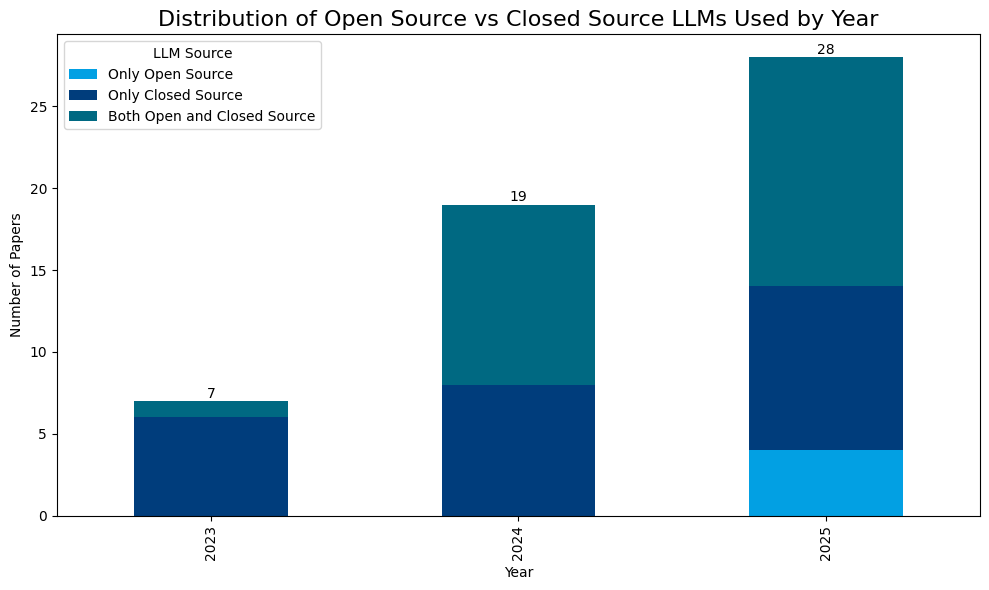

In [36]:
# Plot Stacked bar chart
plt.figure(figsize=(10, 6))
source_counts_by_year.set_index('Year')[['Only Open Source', 'Only Closed Source', 'Both Open and Closed Source']].plot(kind='bar', stacked=True, ax=plt.gca())
plt.xlabel('Year')
plt.ylabel('Number of Papers')
plt.title('Distribution of Open Source vs Closed Source LLMs Used by Year', fontsize=16)
plt.legend(title='LLM Source', loc='upper left')
for i, row in source_counts_by_year.iterrows():
    total = row['Only Open Source'] + row['Only Closed Source'] + row['Both Open and Closed Source']
    plt.text(i, total + 0.2, str(total), color='black', ha='center')    
plt.tight_layout()
plt.show()

In [37]:
# # Plot the distribution of specific model families over the years
# model_families = list(model_rules.keys())
# model_family_yearly_counts = df_models_source.groupby('Year')[model_families].sum().reset_index()
# model_family_yearly_counts_melted = model_family_yearly_counts.melt(id_vars='Year', value_vars=model_families, var_name='Model Family', value_name='Count')
# plt.figure(figsize=(8, 6))
# sns.barplot(x='Year', y='Count', hue='Model Family', data=model_family_yearly_counts_melted,
#             # use viridis opposite colors for better visibility
#             # palette=sns.color_palette("viridis", n_colors=len(model_families)).as_hex()
#             )
# plt.xlabel('Year')
# plt.ylabel('Number of Papers')
# # the y-axis ticks should only be integers instead of floats
# plt.yticks(range(0, model_family_yearly_counts_melted['Count'].max() + 1))

# plt.title('Distribution of Specific LLM Model Families Used Over Time', fontsize=16)
# # legend outside the plot
# plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

# plt.tight_layout()
# save_figure("Specific_LLM_Model_Families_Over_Time")
# plt.show()

### OpenAI Models

In [38]:
# Define specific patterns for OpenAI models
patterns_openai = {
    # "GPT-4": r"(?i)\b(?:chat\s*)?gpt[- ]?4(?![- ]?(?:1|5|o|o[- ]?mini|1[- ]?mini|5|turbo))\b",
    "GPT-4": r"(?i)\b(?:chat\s*)?gpt[- ]?4(?![.\- ]?(?:1|5|o|turbo|mini))\b",
    "GPT-4.1": r"(?i)\bgpt[- ]?4(?:\.1| 1)(?![- ]?mini)\b",
    "GPT-4.1-mini": r"(?i)\bgpt[- ]?4(?:\.1| 1)[- ]?mini\b",
    "GPT-4o-mini": r"(?i)\bgpt[- ]?4o[- ]?mini\b",
    "GPT-4o": r"(?i)\bgpt[- ]?4o(?![- ]?mini)\b",
    "GPT-4.5": r"(?i)\bgpt[- ]?4[. ]5\b",
    "GPT-4-Turbo": r"(?i)\bgpt[- ]?4(?:[. ]5|5)?[- ]?turbo\b",
    "o3": r"(?i)\bo3[- ]?mini\b",
    "o1": r"(?i)\bo1[- ]?mini\b",
    "GPT-3.5-Turbo": r"(?i)\b(?:chat\s*)?gpt[- ]?3(?:[. ]5|5)[- ]?turbo\b",
    "GPT-3.5": r"(?i)\b(?:chat\s*)?gpt[- ]?3(?:[. ]5|5)(?![- ]?turbo)\b",
    "GPT-3": r"(?i)\b(?:chat\s*)?gpt[- ]?3(?![ \-]?(?:5|\.5))(?![ \-]?5[ \-]?turbo)\b",
    "GPT-2": r"(?i)\bgpt[- ]?2\b",
    "Text-Davinci": r"(?i)\btext[- ]davinci\b|\b(?:davinci)\b",
    "Text-Embedding": r"(?i)\btext[- ]embedding[- ]ada\b",
}

In [39]:
# Extract specific GPT models
df_gpt_models = df_models[df_models['OpenAI GPT Family'] == 1][['Title', 'LLMs Used']]

for model_name, pattern in patterns_openai.items():
    df_gpt_models[model_name] = df_gpt_models['LLMs Used'].apply(
        lambda x: int(bool(re.search(pattern, str(x).lower())))
    )

# Count
gpt_model_counts = df_gpt_models[patterns_openai.keys()].sum().reset_index()
gpt_model_counts.columns = ['GPT Model', 'Count']
gpt_model_counts = gpt_model_counts.sort_values('GPT Model')
gpt_model_counts = gpt_model_counts.sort_values('Count', ascending=False).reset_index(drop=True)
gpt_model_counts = gpt_model_counts[gpt_model_counts['Count'] > 0].reset_index(drop=True)

In [40]:
# # Plot the distribution of specific GPT models used
# plt.figure(figsize=(8, 6))
# sns.barplot(x='Count', y='GPT Model', data=gpt_model_counts)
# plt.xlabel('Number of Papers')
# plt.ylabel('')
# plt.title('Distribution of Specific OpenAI Models Used', fontsize=16)
# for i, v in enumerate(gpt_model_counts['Count']):
#     plt.text(v + 0.2, i, str(v), color='black', va='center')
# plt.tight_layout()
# plt.show()

#### Check Version Date

In [41]:
def analyze_openai_versions(cell):
    if pd.isna(cell):
        return pd.Series([0, 0, 0])
    
    # Split models
    models = re.split(r'\n|- ', cell)
    
    openai_count = 0
    missing_count = 0
    
    for m in models:
        m = m.lower()
        
        if "model name" in m:
            is_openai = ("gpt" in m) or ("chatgpt" in m)
            
            if is_openai:
                openai_count += 1
                
                if "version or release date = nr" in m:
                    missing_count += 1
    
    flag = 1 if missing_count > 0 else 0
    
    return pd.Series([openai_count, missing_count, flag])

df = df_extraction_table[['Title', 'LLMs Used - Original']].copy()
df[["OpenAI_models_count",
    "OpenAI_missing_version_count",
    "OpenAI_missing_version_flag"]] = df["LLMs Used - Original"].apply(analyze_openai_versions)

# Count papers that use OpenAI models and have missing version/release date information
num_openai_models = df["OpenAI_models_count"].sum()
num_missing_version = df["OpenAI_missing_version_count"].sum()
num_missing_version_flag = df["OpenAI_missing_version_flag"].sum()

print(f"Number of papers that use OpenAI models: {num_openai_models}")
print(f"Number of papers that have missing version/release date information for OpenAI models: {num_missing_version}")
print(f"Number of papers that have at least one OpenAI model with missing version/release date information: {num_missing_version_flag}")

Number of papers that use OpenAI models: 64
Number of papers that have missing version/release date information for OpenAI models: 47
Number of papers that have at least one OpenAI model with missing version/release date information: 33


### Llama Models

In [42]:
# Define more specific patterns for Llama models
patterns_llama = {
    "Llama-4-400b": r"llama[-.\s/]*4(?:[-.\s/]*maverick)?[-.\s/]*\(?\s*400b\s*\)?(?![a-z0-9])",
    "Llama-4-107b": r"llama[-.\s/]*4(?:[-.\s/]*scout)?[-.\s/]*\(?\s*107b\s*\)?(?![a-z0-9])",

    "Llama-3.3-70b": r"(?<![a-z0-9])llama[-.\s/]*3(?:[-.\s/]*3|\.3)[-.\s/]*\(?\s*70b\s*\)?(?![a-z0-9])",
    "Llama-3.2-90b": r"(?<![a-z0-9])llama[-.\s/]*3(?:[-.\s/]*2|\.2)[-.\s/]*\(?\s*90b\s*\)?(?![a-z0-9])",
    "Llama-3.2-11b": r"(?<![a-z0-9])llama[-.\s/]*3(?:[-.\s/]*2|\.2)[-.\s/]*\(?\s*11b\s*\)?(?![a-z0-9])",
    "Llama-3.2-3b":  r"(?<![a-z0-9])llama[-.\s/]*3(?:[-.\s/]*2|\.2)[-.\s/]*\(?\s*3b\s*\)?(?![a-z0-9])",
    "Llama-3.2-1b":  r"(?<![a-z0-9])llama[-.\s/]*3(?:[-.\s/]*2|\.2)[-.\s/]*\(?\s*1b\s*\)?(?![a-z0-9])",
    # "Llama-3.2":     r"(?<![a-z0-9])llama[-.\s/]*3(?:[-.\s/]*2|\.2)(?![-.\s/]*\(?\s*(?:1b|3b|11b|90b)\s*\)?)(?![a-z0-9])",
    "Llama-3.2": r"(?<![a-z0-9])llama[-.\s/]*3(?:[-.\s/]*2|\.2)(?![-.\s/]*\(?\s*(?:90b|11b|3b|1b)\s*\)?)(?![a-z0-9])",
    
    "Llama-3.1-405b": r"(?<![a-z0-9])llama[-.\s/]*3(?:[-.\s/]*1|\.1)[-.\s/]*\(?\s*405b\s*\)?(?![a-z0-9])",
    "Llama-3.1-70b":  r"(?<![a-z0-9])llama[-.\s/]*3(?:[-.\s/]*1|\.1)[-.\s/]*\(?\s*70b\s*\)?(?![a-z0-9])",
    "Llama-3.1-13b":  r"(?<![a-z0-9])llama[-.\s/]*3(?:[-.\s/]*1|\.1)[-.\s/]*\(?\s*13b\s*\)?(?![a-z0-9])",
    "Llama-3.1-8b":   r"(?<![a-z0-9])llama[-.\s/]*3(?:[-.\s/]*1|\.1)[-.\s/]*\(?\s*8b\s*\)?(?![a-z0-9])",
    "Llama-3.1-7b":   r"(?<![a-z0-9])llama[-.\s/]*3(?:[-.\s/]*1|\.1)[-.\s/]*\(?\s*7b\s*\)?(?![a-z0-9])",
    # "Llama-3.1":      r"(?<![a-z0-9])llama[-.\s/]*3(?:[-.\s/]*1|\.1)(?![-.\s/]*\(?\s*(?:7b|8b|13b|70b|405b)\s*\)?)(?![a-z0-9])",
    "Llama-3.1": r"(?<![a-z0-9])llama[-.\s/]*3(?:[-.\s/]*1|\.1)(?![-.\s/]*\(?\s*(?:405b|70b|13b|8b|7b)\s*\)?)(?![a-z0-9])",

    "Llama-3-70b": r"(?<![a-z0-9])llama[-.\s/]*3(?![-.\s/]*(?:1|2|3|\.))(?:[-.\s/]*\(?\s*70b\s*\)?)(?![a-z0-9])",
    "Llama-3-8b":  r"(?<![a-z0-9])llama[-.\s/]*3(?![-.\s/]*(?:1|2|3|\.))(?:[-.\s/]*\(?\s*8b\s*\)?)(?![a-z0-9])",
    "Llama-3-7b":  r"(?<![a-z0-9])llama[-.\s/]*3(?![-.\s/]*(?:1|2|3|\.))(?:[-.\s/]*\(?\s*7b\s*\)?)(?![a-z0-9])",
    "Llama-2-70b": r"(?<![a-z0-9])llama[-.\s/]*2[-.\s/]*\(?\s*70b\s*\)?(?![a-z0-9])",
    "Llama-2-13b": r"(?<![a-z0-9])llama[-.\s/]*2[-.\s/]*\(?\s*13b\s*\)?(?![a-z0-9])",
    "Llama-2-7b":  r"(?<![a-z0-9])llama[-.\s/]*2[-.\s/]*\(?\s*7b\s*\)?(?![a-z0-9])",
    "Llama-1-65b": r"(?<![a-z0-9])llama(?:[-.\s/]*1)?[-.\s/]*\(?\s*65b\s*\)?(?![a-z0-9])",
    "Llama-1-33b": r"(?<![a-z0-9])llama(?:[-.\s/]*1)?[-.\s/]*\(?\s*33b\s*\)?(?![a-z0-9])",
    "Llama-1-30b": r"(?<![a-z0-9])llama(?:[-.\s/]*1)?[-.\s/]*\(?\s*30b\s*\)?(?![a-z0-9])",
    "Llama-1-13b": r"(?<![a-z0-9])llama(?:[-.\s/]*1)?[-.\s/]*\(?\s*13b\s*\)?(?![a-z0-9])",
    "Llama-1-7b":  r"(?<![a-z0-9])llama(?:[-.\s/]*1)?[-.\s/]*\(?\s*7b\s*\)?(?![a-z0-9])",
}

patterns_llama_flatten = {
    "Llama-4": (
        r"\b(?:llama\s+4|llama 4)\s+(?:maverick|scout)\b"
    ),
    
    "Llama-3.3": (
        r"\b(?:llama\s+3\.3|llama 3 3|llama3 3|llama-3.3)\b(?:\s+(?:70b|8b|405b))?"
    ),
    
    "Llama-3.1": (
        r"\b(?:llama\s+3\.1|llama 3 1|llama3 1|llama-3.1)\b"
        r"(?:\s+(?:8b|70b|405b|japanese-instruct-2407))?"
    ),
    
    "Llama-3": (
        r"\b(?:llama\s+3|llama 3|llama3)\b"
        r"(?!\s+(?:3\.1|3 1))"
        r"(?:\s+(?:8b|70b|70b-instruct|8b-instruct|8b-base|chinese-8b-instruct))?"
    ),
    
    "Llama-2": (
        r"\b(?:llama\s+2|llama 2|llama-2)\b"
        r"(?:\s+(?:7b|13b|70b)(?:\s+(?:chat|chat-hf|instruct|base))?)?"
    ),
    
}

In [43]:
# Create binary columns for model
df_llama_models = df_models[df_models['Llama Family'] == 1][['Title', 'LLMs Used']]
for model_name, pattern in patterns_llama.items():
    df_llama_models[model_name] = df_llama_models['LLMs Used'].apply(
        lambda x: int(bool(re.search(pattern, str(x).lower())))
    )

# Count
llama_model_counts = df_llama_models[patterns_llama.keys()].sum().reset_index()
llama_model_counts.columns = ['Llama Model', 'Count']
# llama_model_counts = llama_model_counts[llama_model_counts['Count'] > 0]
# desired_order = ["Llama-1-7b", "Llama-2-7b", "Llama-2-13b", "Llama-3-7b", "Llama-3-8b", "Llama-3-70b",
#                  "Llama-3.1-7b", "Llama-3.1-8b", "Llama-3.1-70b", "Llama-3.1-405b", "Llama-3.3-70b", "Llama-4-400b"]
# llama_model_counts['Llama Model'] = pd.Categorical(llama_model_counts['Llama Model'], categories=desired_order, ordered=True)
# llama_model_counts = llama_model_counts.sort_values('Llama Model').reset_index(drop=True)
# remove rows with 0 count
llama_model_counts = llama_model_counts[llama_model_counts['Count'] > 0].reset_index(drop=True)
# sort count by descending order
llama_model_counts = llama_model_counts.sort_values('Count', ascending=False).reset_index(drop=True)
llama_model_counts

,Llama Model,Count
0,Llama-3-8b,8
1,Llama-3-70b,5
2,Llama-3.1-8b,4
3,Llama-2-13b,3
4,Llama-3.1-70b,3
5,Llama-3.3-70b,1
6,Llama-3.1-405b,1
7,Llama-3.1,1
8,Llama-2-7b,1


### Plot

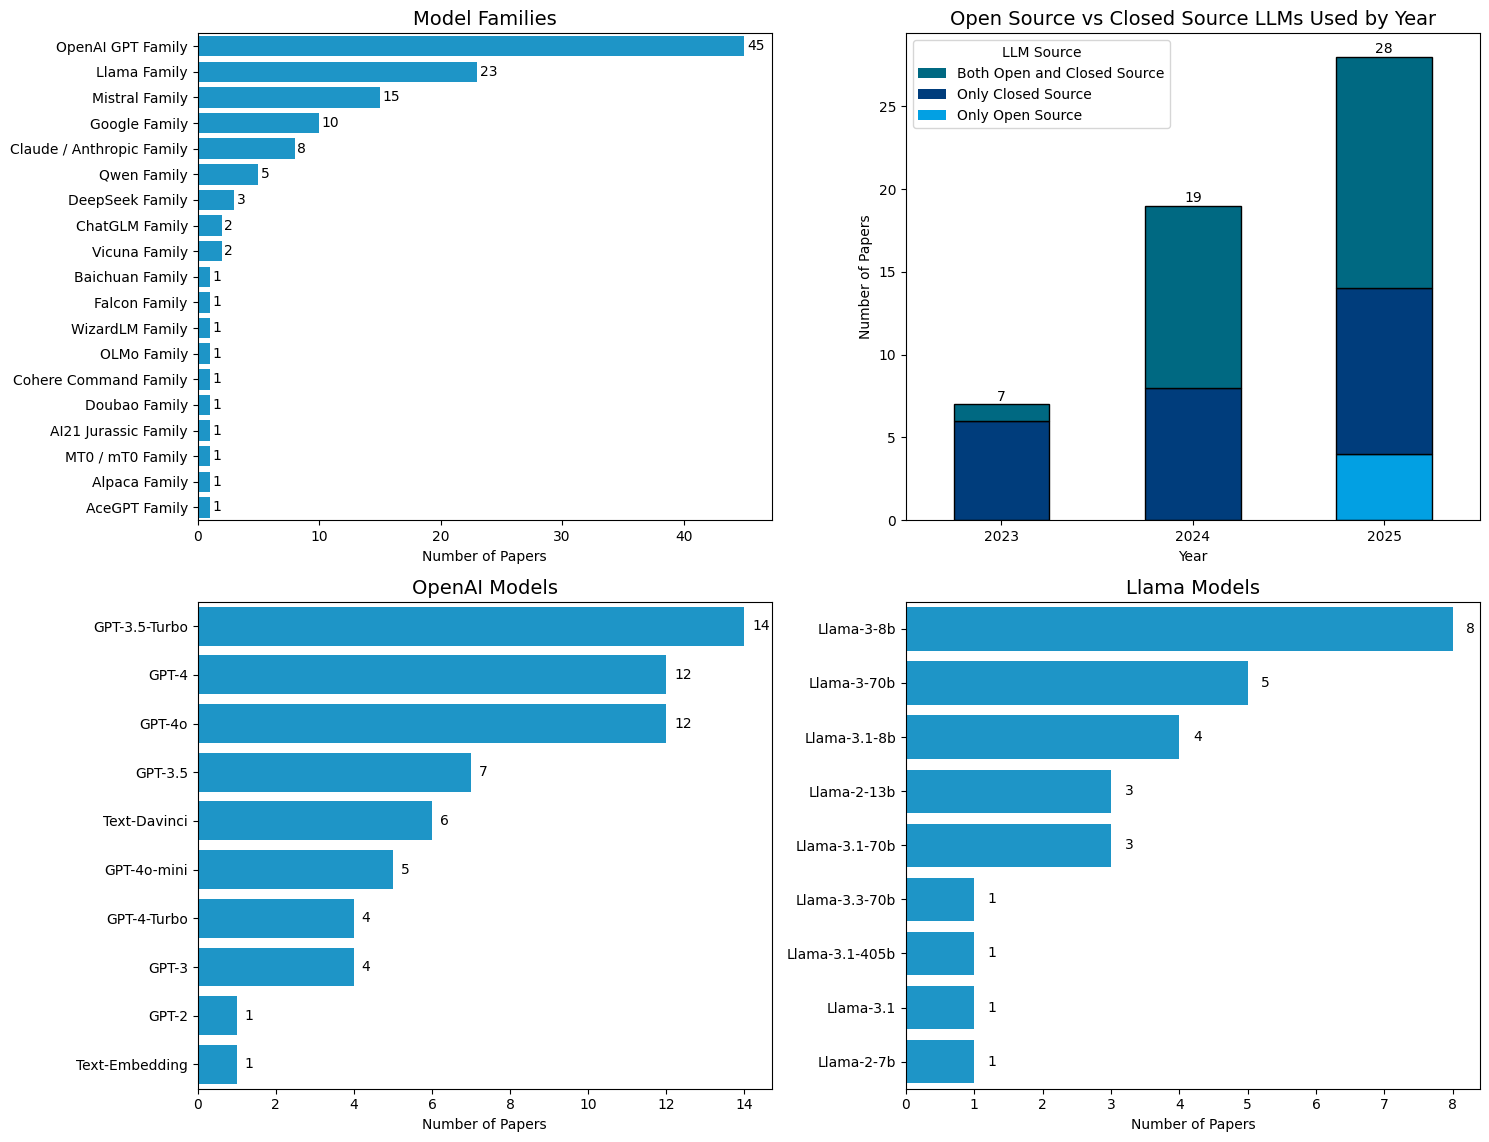

In [44]:
# Plot all 4 figures together in a 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
axes = axes.flatten()

# fig.suptitle('Distribution of LLMs Used Across Papers', fontsize=16)

# First subplot: Model Families
sns.barplot(x='Count', y='Model Family', data=model_family_counts, ax=axes[0])
axes[0].set_xlabel('Number of Papers')
axes[0].set_ylabel('')
axes[0].set_title('Model Families', fontsize=14)
for i, v in enumerate(model_family_counts['Count']):
    axes[0].text(v + 0.2, i, str(v), color='black', va='center')

# Second subplot: Open Source vs Closed Source vs Both by Year
source_counts_by_year.set_index('Year')[['Only Open Source', 'Only Closed Source', 'Both Open and Closed Source']].plot(kind='bar', stacked=True, ax=axes[1])
axes[1].set_xlabel('Year')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)
axes[1].set_ylabel('Number of Papers')
axes[1].set_title('Open Source vs Closed Source LLMs Used by Year', fontsize=14)
axes[1].legend(title='LLM Source', loc='upper left')
# Order the legend displays
handles, labels = axes[1].get_legend_handles_labels()
order = [2, 1, 0]  # new order of legend items
axes[1].legend([handles[i] for i in order], [labels[i] for i in order], title='LLM Source', loc='upper left')
for i, row in source_counts_by_year.iterrows():
    total = row['Only Open Source'] + row['Only Closed Source'] + row['Both Open and Closed Source']
    axes[1].text(i, total + 0.2, str(total), color='black', ha='center')
for container in axes[1].containers:
    for patch in container.patches:
        patch.set_edgecolor('black')
        patch.set_linewidth(1)

# Third subplot: OpenAI GPT Models
sns.barplot(x='Count', y='GPT Model', data=gpt_model_counts, ax=axes[2])
axes[2].set_xlabel('Number of Papers')
axes[2].set_ylabel('')
axes[2].set_title('OpenAI Models', fontsize=14)
axes[2].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
for i, v in enumerate(gpt_model_counts['Count']):
    axes[2].text(v + 0.2, i, str(v), color='black', va='center')
# Fourth subplot: Llama Models
sns.barplot(x='Count', y='Llama Model', data=llama_model_counts, ax=axes[3])
axes[3].set_xlabel('Number of Papers')
axes[3].set_ylabel('')
axes[3].set_title('Llama Models', fontsize=14)
for i, v in enumerate(llama_model_counts['Count']):
    axes[3].text(v + 0.2, i, str(v), color='black', va='center')

plt.tight_layout(rect=[0, 0, 1, 0.96])
save_figure("Distribution_of_LLMs_all")
plt.show()

## Persona-Construction Strategies

### General Approach

In [45]:
# Extracting LLM Persona Construction Strategies

# Define the patterns
patterns_methods = {
    "Prompt Engineering": r"\bprompt\s+engineering\b",
    "Model-level Fine-Tuning": r"\b(?:model[-\s]?level|full)?\s*fine[-\s]?tuning\b",
}

# Create binary columns for each method
df_methods = df_extraction_table[['Title', 'LLM Persona Adaptation Strategy']].copy()
for method, pattern in patterns_methods.items():
    df_methods[method] = df_methods['LLM Persona Adaptation Strategy'].apply(
        lambda x: int(bool(re.search(pattern, str(x).lower())))
    )
# Ensure that if a paper uses Model-level Fine-Tuning, it is not also counted as using Prompt Engineering
df_methods.loc[df_methods['Model-level Fine-Tuning'] == 1, 'Prompt Engineering'] = 0

method_counts = df_methods[patterns_methods.keys()].sum().reset_index()
method_counts.columns = ['Method', 'Count']
method_counts = method_counts.sort_values('Count', ascending=False).reset_index(drop=True)
method_counts

,Method,Count
0,Prompt Engineering,47
1,Model-level Fine-Tuning,8


### Fine-Tuning Input

In [46]:
# Define patterns for training data types
patterns_trainingdata = {
    "Self-reported data": r"\bsurvey\s+data\b",
    "External: \nSocial Media Data": r"\bsocial\s+media\b",
    "External: \nConversation Data": r"\bsurvey\s+data\b.*\bconversation\s+data\b|\bconversation\s+data\b.*\bsurvey\s+data\b"
}

# Analyze the Training Dataset column
df_trainingdata = df_extraction_table[df_extraction_table['LLM Persona Adaptation Strategy'].apply(lambda x: bool(re.search(r"\bmodel[-\s]?level\s*fine[-\s]?tuning\b", str(x).lower())))][['Title', 'Training Dataset']].copy()

# Create binary columns 
for data_type, pattern in patterns_trainingdata.items():
    df_trainingdata[data_type] = df_trainingdata['Training Dataset'].apply(
        lambda x: int(bool(re.search(pattern, str(x).lower())))
    )
    
# Count
training_data_counts = df_trainingdata[patterns_trainingdata.keys()].sum().reset_index()
training_data_counts.columns = ['Training Data Type', 'Count']
training_data_counts = training_data_counts.sort_values('Count', ascending=False).reset_index(drop=True)

training_data_counts

,Training Data Type,Count
0,Self-reported data,7
1,External: \nSocial Media Data,1
2,External: \nConversation Data,1


In [47]:
# Plot
# plt.figure(figsize=(7, 6))
# sns.barplot(x='Count', y='Training Data Type', data=training_data_counts)
# plt.xlabel('Number of Papers')
# plt.ylabel('')
# plt.title('Training Data Types Used in Model-level Fine-Tuning', fontsize=14)
# for i, v in enumerate(training_data_counts['Count']):
#     plt.text(v + 0.1, i, str(v), color='black', va='center')
# plt.tight_layout()
# plt.show()

### Prompting Input

In [48]:
# Define Prompting Patterns
patterns_Prompting = {
    "External Data": {
        "Web Tracked data": r"\b(web usage|web search|browsing|web tracking|url|browser history|tracked data|search history)\b",
        "Media diet": r"\b(social media(?: consumption| use| usage| exposure)?|news(?: use| usage| consumption| exposure)?)\b",
    },
    "Self reported survey data": {
        "Self-reported data: \nDemographic": r"\b(age|gender|education|income|race|occupation|sex|location|urban|rural|ethnic|ethnicity)\b",
        "Self-reported data: \nAttitudes and Beliefs": r"\b(immigration|global warming|gun|abortion|facial recognition|behaviors and preferences|attitude towards|policy|climate)\b",
        "Self-reported data: \nPolitical characteristics": r"\b(party|left or right|left|right|partisanship|ideolog|liberal|conservativ|political attitude|registration|vote|turnout)\b",
        "Self-reported data: \nPsychological traits": r"\b(hexaco|personality|big ?five|psycholog|inventory|scale|anxiet|depress)\b",
    }
}

In [49]:
# Analyze the "LLM Training / Prompting Input"
df_promptinput = df_extraction_table[['Title', 'LLM Training / Prompting Input']].copy()

for category, subcategories in patterns_Prompting.items():
    for subcategory, pattern in subcategories.items():
        column_name = f"{category} - {subcategory}"
        df_promptinput[column_name] = df_promptinput['LLM Training / Prompting Input'].apply(
            lambda x: int(bool(re.search(pattern, str(x).lower())))
        )

# Count
prompting_counts = df_promptinput[[col for col in df_promptinput.columns if col not in ['Title', 'LLM Training / Prompting Input']]].sum().reset_index()
prompting_counts.columns = ['Prompting Category', 'Count']
prompting_counts = prompting_counts.sort_values('Count', ascending=False).reset_index(drop=True)
prompting_counts[['Data Type', 'Prompt Input']] = prompting_counts['Prompting Category'].str.split(' - ', expand=True)
prompting_counts = prompting_counts[['Data Type', 'Prompt Input', 'Count']]  

prompting_counts = prompting_counts.sort_values(['Data Type', 'Count'], ascending=[False, False]).reset_index(drop=True)

# Consolidate "Media diet" and "Web Tracked data" into a single "External Data" bar
prompting_counts.loc[prompting_counts['Data Type'] == 'External Data', 'Prompt Input'] = 'External Data'
prompting_counts = (prompting_counts.groupby(['Data Type', 'Prompt Input'], as_index=False, sort=False)['Count'].sum())
prompting_counts = prompting_counts.sort_values(['Data Type', 'Count'], ascending=[False, False]).reset_index(drop=True)

In [50]:
# # Test Plot Type 1
# plt.figure(figsize=(10, 8))
# sns.barplot(x='Count', y='Prompt Input',
#             data=prompting_counts, dodge=False)
# plt.xlabel('Count')
# plt.ylabel('Prompt Input')
# plt.title('Distribution of Prompting Inputs Used', fontsize=16)
# for i, v in enumerate(prompting_counts['Count']):
#     plt.text(v + 0.2, i, str(v), color='black', va='center')
# plt.tight_layout()
# plt.show()

In [51]:
# # Test Plot Type 2: with custom braces to group by Data Type and no hue
# fig, ax = plt.subplots(figsize=(10, 8))

# sns.barplot(
#     x='Count', y='Prompt Input', #hue='Data Type',
#     data=prompting_counts, dodge=False, ax=ax
# )

# ax.set_xlabel('Count')
# ax.set_ylabel('')
# ax.set_title('Distribution of Prompting Inputs Used', fontsize=16)

# for i, v in enumerate(prompting_counts['Count']):
#     ax.text(v + 0.2, i, str(v), va='center')

# def draw_brace(ax, y0, y1, x=-1.4, width=0.45, text=None, text_x=-2.9):
#     mid = (y0 + y1) / 2
#     dy = y1 - y0

#     verts = [
#         (x, y0),
#         (x - width, y0),
#         (x - width, mid - dy*0.18),
#         (x, mid - dy*0.06),
#         (x + width*0.25, mid),
#         (x, mid + dy*0.06),
#         (x - width, mid + dy*0.18),
#         (x - width, y1),
#         (x, y1),
#     ]
#     codes = [
#         Path.MOVETO, Path.CURVE3, Path.CURVE3, Path.CURVE3,
#         Path.CURVE3, Path.CURVE3, Path.CURVE3, Path.CURVE3, Path.LINETO
#     ]

#     patch = PathPatch(Path(verts, codes), fill=False, lw=1.6, color='black', clip_on=False)
#     ax.add_patch(patch)

#     if text:
#         ax.text(text_x, mid, text, va='center', ha='right')

# # Adjust these spans to match your grouped rows
# draw_brace(ax, -0.35, 3.35, x=-14.3, text='Self reported\nsurvey data', text_x=-15.0)
# draw_brace(ax, 3.65, 5.35, x=-14.3, text='External Data', text_x=-15.0)

# ax.set_xlim(-3.5, ax.get_xlim()[1])
# plt.show()

### Demographic Input Types

In [52]:
# Define Demographic Patterns
patterns_Demographic = {
    "Age": r"(?i)\b(?:age|year of birth|born in|age group|45 and older|older than|younger than|generation)\b",
    "Sex/Gender": r"(?i)\b(?:sex|gender|male|female|man|woman|men|women|nonbinary|transgender|binary)\b",
    "Race/Ethnicity/Nationality": r"(?i)\b(?:race|racial|ethnic(?:ity)?|country of origin|country of birth|nationality|native language|citizen(?:ship)?|immigrant|migration background)\b",
    "Education": r"(?i)\b(?:education|educational|highest degree|degree|schooling|vocational|isced|ba or higher|college|university|graduate|qualification)\b",
    "Income/Wealth": r"(?i)\b(?:income|household income|financial situation|socio[-\s]?economic|social class|class income|wage|earnings|wealth|poverty)\b",
    "Region/Geography": r"(?i)\b(?:region|state|residence|residential|location|country of residence|country of citizenship|urban(?:icity)?|rural|area|east west germany|continent|north america|europe|asia|africa|oceania|south america)\b",
    "Household/Family": r"(?i)\b(?:household|marital status|married|single|partner|spouse|family composition|children|living arrangement)\b",
    "Occupation/Employment": r"(?i)\b(?:occupation|employment|employed|unemployed|job|work status|career|field of study|profession|labor force|retired|student)\b",
    "Religion/Religiosity": r"(?i)\b(?:religion|religious|religiosity|church attendance|faith|beliefs about vaccines)\b",
}

In [53]:
# Create binary columns for each demographic keyword
df_demographics = df_extraction_table[['Title', 'LLM Training / Prompting Input']].copy()
for category, pattern in patterns_Demographic.items():
    df_demographics[category] = df_demographics['LLM Training / Prompting Input'].apply(
        lambda x: int(bool(re.search(pattern, str(x).lower())))
    )

# Count
demographic_counts = df_demographics[patterns_Demographic.keys()].sum().reset_index()
demographic_counts.columns = ['Demographic Input Type', 'Count']
demographic_counts = demographic_counts.sort_values('Count', ascending=False).reset_index(drop=True)

### Plot

In [54]:
# Function: Draw a left curly braces
def draw_braces(ax, y0, y1, x=-1.4, width=0.45, text=None, text_x=-2.9):
    mid = (y0 + y1) / 2
    dy = y1 - y0

    verts = [
        (x, y0),
        (x - width, y0),
        (x - width, mid - dy*0.18),
        (x, mid - dy*0.06),
        (x + width*0.25, mid),
        (x, mid + dy*0.06),
        (x - width, mid + dy*0.18),
        (x - width, y1),
        (x, y1),
    ]
    codes = [
        Path.MOVETO, Path.CURVE3, Path.CURVE3, Path.CURVE3,
        Path.CURVE3, Path.CURVE3, Path.CURVE3, Path.CURVE3, Path.LINETO
    ]

    patch = PathPatch(Path(verts, codes), fill=False, lw=1.6, color='black', clip_on=False)
    ax.add_patch(patch)

    if text:
        ax.text(text_x, mid, text, va='center', ha='right', rotation=90)

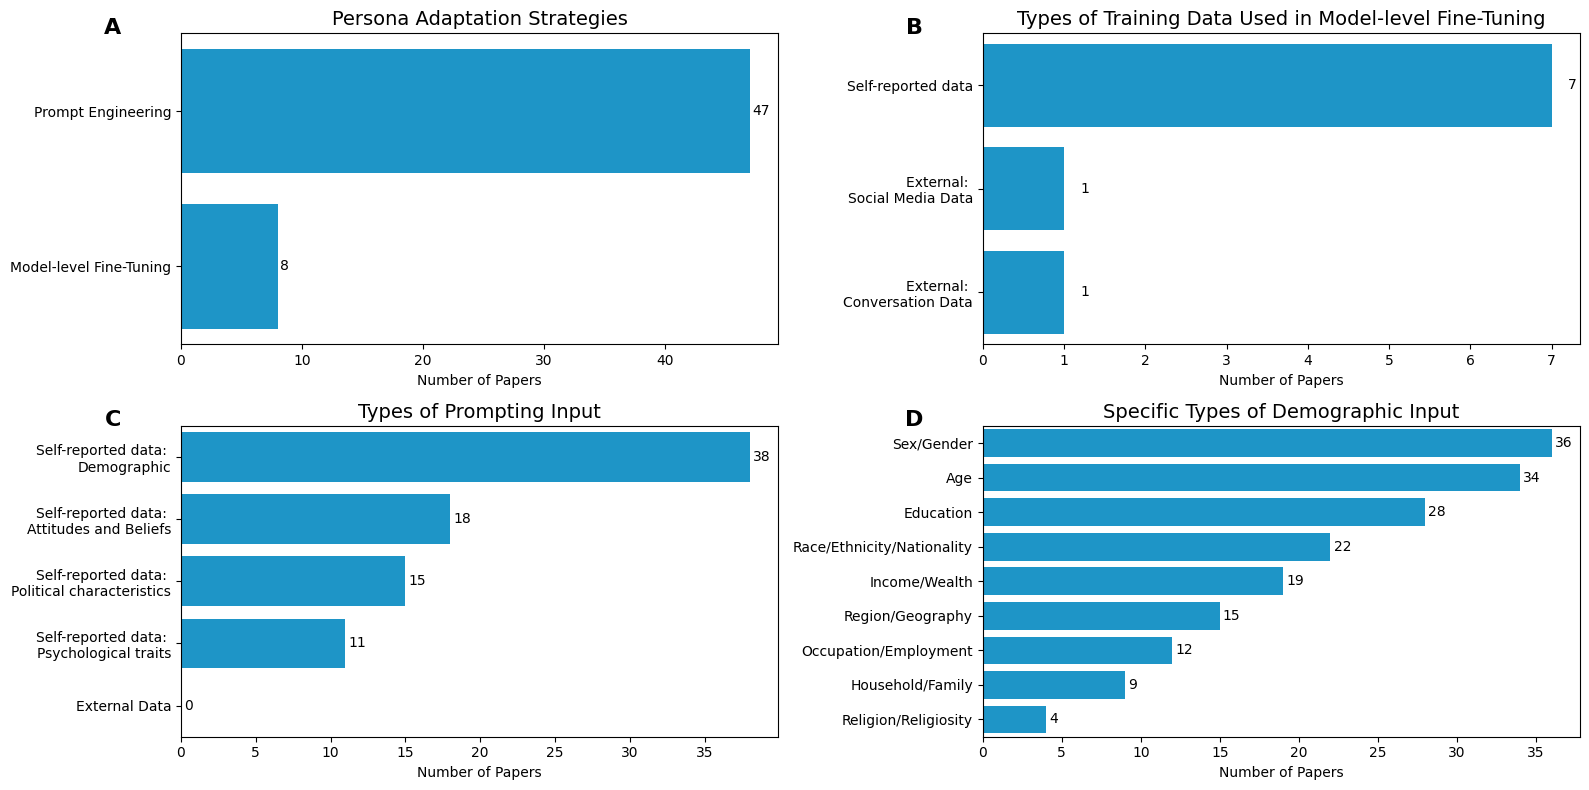

In [55]:
# Plot all four distributions together in a 2 by 2 grid
fig, axes = plt.subplots(2, 2, figsize=(16, 8))
# fig.suptitle('LLM Synthetic Persona Construction Strategies and Prompting Inputs\n', fontsize=18)

# First subplot: General Persona Construction Strategies
sns.barplot(y='Method', x='Count', data=method_counts, ax=axes[0, 0])
axes[0, 0].set_xlabel('Number of Papers')
axes[0, 0].set_ylabel('')
axes[0, 0].set_title('Persona Adaptation Strategies', fontsize=14)
for i, v in enumerate(method_counts['Count']):
    axes[0, 0].text(v + 0.2, i, str(v), color='black', va='center')
axes[0, 0].text(-0.1, 1.05, 'A', transform=axes[0, 0].transAxes, fontsize=16, fontweight='bold', va='top', ha='right')

# Second subplot: Training Data Types
sns.barplot(x='Count', y='Training Data Type', data=training_data_counts, ax=axes[0, 1])
axes[0, 1].set_xlabel('Number of Papers')
axes[0, 1].set_ylabel('')
axes[0, 1].set_title('Types of Training Data Used in Model-level Fine-Tuning', fontsize=14)
for i, v in enumerate(training_data_counts['Count']):
    axes[0, 1].text(v + 0.2, i, str(v), color='black', va='center')
axes[0, 1].text(-0.1, 1.05, 'B', transform=axes[0, 1].transAxes, fontsize=16, fontweight='bold', va='top', ha='right')

# Third subplot: Prompting Strategies
sns.barplot(x='Count', y='Prompt Input', data=prompting_counts, ax=axes[1, 0])
axes[1, 0].set_xlabel('Number of Papers')
axes[1, 0].set_ylabel('')
axes[1, 0].set_title('Types of Prompting Input', fontsize=14)
for i, v in enumerate(prompting_counts['Count']):
    axes[1, 0].text(v + 0.2, i, str(v), color='black', va='center')
axes[1, 0].text(-0.1, 1.05, 'C', transform=axes[1, 0].transAxes, fontsize=16, fontweight='bold', va='top', ha='right')

# Fourth subplot: Demographic Prompting Strategies
sns.barplot(x='Count', y='Demographic Input Type', data=demographic_counts, ax=axes[1, 1])
axes[1, 1].set_xlabel('Number of Papers')
axes[1, 1].set_ylabel('')
axes[1, 1].set_title('Specific Types of Demographic Input', fontsize=14)
for i, v in enumerate(demographic_counts['Count']):
    axes[1, 1].text(v + 0.2, i, str(v), color='black', va='center')
axes[1, 1].text(-0.1, 1.05, 'D', transform=axes[1, 1].transAxes, fontsize=16, fontweight='bold', va='top', ha='right')

plt.tight_layout()
save_figure("Distribution_of_Persona_Construction_Strategies")
plt.show()

## Training Data & Training Specifications

In [59]:
# What training datasets are being used?

# First filter for papers that use model-level fine-tuning
df_finetuning = df_extraction_table[df_extraction_table['LLM Persona Adaptation Strategy'].apply(lambda x: bool(re.search(r"\bmodel[-\s]?level\s*fine[-\s]?tuning\b", str(x).lower())))][[
    'Title',
    # 'LLM Persona Adaptation Strategy', 
    'Training Dataset', 
    'Training Dataset Size']].copy()

In [60]:
# What are the common training dataset sizes?
df_training_size = (
    df_extraction_table.loc[
        ~df_extraction_table["Training Dataset Size"]
        .astype("string")
        .str.contains(r"\b'?not\s+applicable\b|\bnot\s+reported\b", case=False, na=False),
        ["Title", "Training Dataset Size"]
    ]
    .copy()
)

print(f'Number of papers that report a training dataset size: {df_training_size.shape[0]}')
# print(f'\nUnique values in the "Training Dataset Size" column:\n{df_training_size["Training Dataset Size"].unique()}')

Number of papers that report a training dataset size: 19


In [61]:
# Extract the numbers
df_training_size["Training Dataset Size Numbers"] = df_training_size["Training Dataset Size"].astype("string").str.findall(r"\d[\d,]*\.?\d*").apply(lambda xs: "; ".join(xs) if isinstance(xs, list) and len(xs) > 0 else pd.NA)

df_training_size

,Title,Training Dataset Size,Training Dataset Size Numbers
0,Adaptive political surveys and GPT-4: Tackling...,400 entries,400
5,Balancing Large Language Model Alignment and A...,Trillions of tokens of natural language text,<NA>
7,Beyond Demographics: Aligning Role-playing LLM...,Fine-tuning dataset is formulated as DSFT = {(...,1; 564; 3.5; 0125; 3; 1; 2.
8,Beyond Demographics: Enhancing Cultural Value ...,"- Number of QA pairs for U.S. culture: 102,800...","102,800; 4,340; 20"
18,Examining the Feasibility of Large Language Mo...,- Number of respondents: 234 (elementary and m...,234; 886; 234; 886
20,Extracting Affect Aggregates from Longitudinal...,"Summary\n- Number of respondents: 21,576\n- Nu...","21,576; 385,000; 512; 21,576; 13,600,000; 2019..."
21,From Values to Opinions: Predicting Human Beha...,Touché23-ValueEval dataset; split 80:10:10 (tr...,23; 80; 10; 10; 7; 7; 6000; 48; 5; 4; 2; 5.; 8; 3
23,How Well Do Simulated Population Samples with ...,"The desired responses (i.e., finetuning labels...",<NA>
26,Jump Starting Bandits with LLM-Generated Prior...,"10,000 synthetic users","10,000"
27,Knowledge of cultural moral norms in large lan...,Three different Fine-tuning methods and theref...,"1; 80; 2; 20; 11; 8; 3; 20; 4; 2; 81,200; 82,6..."


## Distribution of Alignment Methods

### Level of Evaluation

- Individual
- Distributional 
    - subset of Relational Alignment (4)
- Both Distri & Individual
    - subset of Relational Alignment (3)

In [62]:
# Define patterns for Alignment Methods
patterns_alignment = {
    "Individual-level Alignment": r"\bindividual\b",
    "Aggregated-distributional level Alignment": r"\baggregated\b"
}

df_alignment = df_extraction_table[['Title', 'Authors','Level of Alignment', 'Relational Alignment']].copy()
for method, pattern in patterns_alignment.items():
    df_alignment[method] = df_alignment['Level of Alignment'].apply(
        lambda x: int(bool(re.search(pattern, str(x).lower())))
    )

df_alignment['Relational Alignment'] = (df_alignment['Relational Alignment'].str.lower().eq('yes').astype(int))

df_alignment['Both Alignment Levels'] = df_alignment.apply(lambda row: 1 if row['Individual-level Alignment'] == 1 and row['Aggregated-distributional level Alignment'] == 1 else 0, axis=1)
# Ensure that if a paper is counted as "Both Alignment Levels", it is not also counted in the individual categories or the aggregated category
df_alignment.loc[df_alignment['Both Alignment Levels'] == 1, ['Individual-level Alignment', 'Aggregated-distributional level Alignment']] = 0


# Count also the papers that uses Relational Alignment and Aggregated-distributional level Alignment, or also Relational Alignment and Both Alignment Levels, to see if there is any overlap
df_alignment['Relational + Aggregated Alignment'] = df_alignment.apply(lambda row: 1 if row['Relational Alignment'] == 1 and row['Aggregated-distributional level Alignment'] == 1 else 0, axis=1)
df_alignment['Relational + Both Alignment'] = df_alignment.apply(lambda row: 1 if row['Relational Alignment'] == 1 and row['Both Alignment Levels'] == 1 else 0, axis=1)
df_alignment['Relational + Individual Alignment'] = df_alignment.apply(lambda row: 1 if row['Relational Alignment'] == 1 and row['Individual-level Alignment'] == 1 else 0, axis=1)

# Count
alignment_counts = df_alignment[['Individual-level Alignment', 
                                 'Aggregated-distributional level Alignment', 
                                 'Both Alignment Levels',
                                 'Relational Alignment',
                                 'Relational + Aggregated Alignment',
                                 'Relational + Both Alignment',
                                 'Relational + Individual Alignment']].sum().reset_index()
alignment_counts.columns = ['Alignment Type', 'Count']

alignment_counts = alignment_counts.sort_values('Count', ascending=False).reset_index(drop=True)
alignment_counts

,Alignment Type,Count
0,Aggregated-distributional level Alignment,38
1,Individual-level Alignment,9
2,Both Alignment Levels,8
3,Relational Alignment,7
4,Relational + Aggregated Alignment,4
5,Relational + Both Alignment,3
6,Relational + Individual Alignment,0


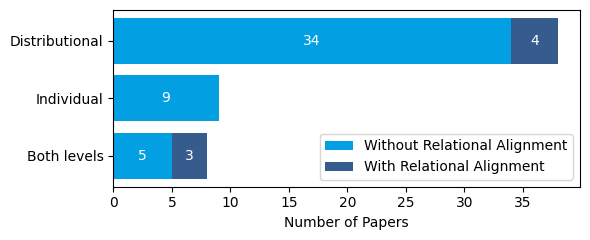

In [63]:
# Plot

# Prepare data for plotting
plot_data = {
    "Distributional": {
        "pure":      df_alignment['Aggregated-distributional level Alignment'].sum(),
        "relational": df_alignment['Relational + Aggregated Alignment'].sum(),
    },
    "Individual": {
        "pure":      df_alignment['Individual-level Alignment'].sum(),
        "relational": df_alignment['Relational + Individual Alignment'].sum(),
    },
    "Both levels": {
        "pure":      df_alignment['Both Alignment Levels'].sum(),
        "relational": df_alignment['Relational + Both Alignment'].sum(),
    },
}
plot_df = pd.DataFrame(plot_data).T.reset_index().rename(columns={'index': 'Alignment Type'})
plot_df['pure'] = plot_df['pure'] - plot_df['relational']
color_pure = sns.color_palette('viridis')[0] 
color_relational = sns.color_palette('viridis')[1]
plt.figure(figsize=(6, 2.5))
plt.barh(plot_df['Alignment Type'], plot_df['pure'], label='Without Relational Alignment')
plt.barh(plot_df['Alignment Type'], plot_df['relational'], left=plot_df['pure'], 
         color=color_relational, label='With Relational Alignment')
plt.xlabel('Number of Papers')
plt.gca().invert_yaxis()       
plt.legend(loc='lower right')
# plt.title('Alignment Methods Used in Papers', fontsize=16)
plt.legend()
for index, row in plot_df.iterrows():
    if row['pure'] > 0:
        plt.text(row['pure'] / 2, index, str(row['pure']), va='center', ha='center', color='white')
    if row['relational'] > 0:
        plt.text(row['pure'] + row['relational'] / 2, index, str(row['relational']), va='center', ha='center', color='white')
plt.tight_layout()
save_figure("Distribution_of_Alignment_Methods")
plt.show()

## Distribution of Evaluation Strategies

In [64]:
# Define metrics taxonomy
metrics_taxonomy = {
    "Predictive Performance Metrics": {
        "Classification": {
            "Accuracy": ( r"(?i)\baccuracy\b", r"(?i)\b(?:recommendation|detection|prediction)\s+accuracy\b" ),
            "Precision": r"(?i)\b(?:precision|positive\s+predictive\s+value|ppv)\b",
            "Recall": r"(?i)\b(?:recall|sensitivity|true\s+positive\s+(?:rate|recall)|tpr)\b",
            "F1 score": r"(?i)\b(?:f1(?:[-\s]?score)?|f[-]?score|macro(?:[-\s]?average\s+)?f1|micro\s+f1|maf1)\b",
            "AUC": r"(?i)\b(?:auc(?:\s*\(?roc\)?)?|roc\s*auc|area\s+under\s+(?:the\s+)?curve)\b",
        },
        "Regression / Continuous": {
            "MAE": r"(?i)\b(?:mae|mean\s+absolute\s+(?:error|deviation)|mad)\b",
            "MSE": r"(?i)\b(?:mse|mean\s+squared\s+error|mspe|mean\s+squared\s+prediction\s+error)\b",
            "RMSE": r"(?i)\b(?:rmse|root\s+mean\s+squared\s+error)\b",
            "MAPE": r"(?i)\b(?:mape|mean\s+absolute\s+percentage\s+error)\b",
            "NMSE": r"(?i)\b(?:nmse|normalized\s+mean\s+squared\s+error)\b",
        },
        "Regret Measurements": {
            "Regret": r"(?i)\b(?:regret|cumulative\s+regret|accumulated\s+regret|reduction\s+in\s+cumulative\s+regret)\b",
        },
    },
    
    "Agreement & Reliability Metrics": {
        "Inter-rater Agreement": {
            "Cohen's kappa": r"(?i)\b(?:cohen(?:'s)?\s+kappa|cohens?\s+kappa)\b",
            "Fleiss' kappa": r"(?i)\b(?:fleiss(?:'s)?\s+kappa|fleiss\s+kappa)\b",
            "Quadratic weighted kappa": r"(?i)\b(?:quadratic\s+weighted\s+kappa|qwk)\b",
            "Proportion agreement": r"(?i)\b(?:proportion\s+agreement|agreement\s+(?:ratio|proportion)|percent\s+agreement)\b",
        },
        "Reliability & Consistency": {
            "Cronbach's alpha": r"(?i)\b(?:cronbach(?:'s)?\s+alpha|cronbach(?:['’]s)?\s*(?:alpha|α)|cronbachs|cronbachs?\s+alpha|internal\s+consistency)\b",
            "Intraclass correlation coefficient": r"(?i)\b(?:intraclass\s+correlation\s+(?:coefficient|icc)|icc)\b",
        },
    },
    
    "Correlation Metrics": {
        "Correlation Metrics": {
            "Correlation (not specified)": r"(?i)\b(?:correlations?\s+analysis|correlation)\b",
            "Pearson correlation": r"(?i)\b(?:pearson(?:\s+correlation(?:\s+coefficient)?)?|pearson\s*r)\b",
            "Spearman correlation": r"(?i)\b(?:spearman(?:\s+correlation(?:\s+coefficient)?)?|spearman\s*rho)\b",
            "Rank correlation": r"(?i)\b(?:rank\s+correlation|kendall(?:'s)?\s+tau)\b",
            "Partial correlation": r"(?i)\b(?:partial\s+correlation)\b",
            "Tetrachoric correlation": r"(?i)\b(?:tetrachoric\s+correlation)\b",
            "Procrustes correlation": r"(?i)\b(?:procrustes(?:\s+(?:correlation|analysis|distance))?)\b",
            "Cramér's V": r"(?i)\b(?:cram[eé]r(?:'s)?\s+v|cramers?\s+v|cramer(?:'s)?\s+phi)\b",
        },
    },
    
    "Distribution Comparison Metrics": {
        "Distance & Divergence": {
            # "Wasserstein distance": r"(?i)\b(?:wasserstein(?:\s+distance)?|earth\s+mover(?:'s)?(?:\s+distance)?|emd|nemd)\b",
            "Wasserstein distance": r"(?i)\b(?:wass(?:a)?erstein(?:\s+distance)?|earth\s+mover(?:'s)?(?:\s+distance)?|emd|nemd)\b",
            "KL divergence": r"(?i)\b(?:kl\s*divergence|kullback[-\s]?leibler(?:\s+divergence)?|forward\s+kl)\b",
            "Jensen-Shannon divergence": r"(?i)\b(?:jensen[-\s]?shannon(?:\s+(?:divergence|distance))?|jsd)\b",
            "Total variation distance": r"(?i)\b(?:total\s+variation\s+(?:distance|divergence)|tvd)\b",
            "Cross-entropy": r"(?i)\b(?:cross[-\s]?entropy)\b",
            "Entropy": ( r"(?i)\b(?:" r"entropy(?!\s+(?:based|model))|" r"conditional\s+entropy|" r"information\s+gain|" r"mutual\s+information" r")\b" ),
        },
    },
    
    "Descriptive Statistics": {
        "Descriptive Statistics": {
            "Descriptive Statistics": (
                r"(?i)\b(?:"
                r"(?<!\broot\s)(?:mean|means)(?!\s+(?:absolute|squared|error|absolute\s+percentage|absolute\s+deviation|squared\s+prediction|f1))|"
                r"average(?!\s+(?:absolute|squared|error|f1))|"                
                r"variance|var|" # Variance
                r"standard\s+deviations?|std|sd|" # Standard deviation                
                r"descriptive\s+stati(?:stics|stical)|descriptives|summary\s+statistics|" # Descriptive statistics labels                
                r"mean\s+(?:difference|matching)|difference\s+in\s+means|" # Mean difference 
                r"variance\s+(?:difference|matching)|std\s+(?:difference|matching)|" # Variance difference
                r"outlier(?:\s+(?:identification|detection))?|"  # Z-score / Outlier
                r"z[- ]score(?:\s+(?:threshold|cut[- ]off|exceed(?:ing)?))?|"
                r"absolute\s+(?:difference\s+in\s+)?z[- ]score"
                r")\b"
            ),
        },
    },
    
    "Statistical Inference": { 
        "Hypothesis Tests": {
            "t-test": r"(?i)\b(?:t[-\s]?test|welch(?:es)?\s+t[-\s]?test|paired\s+t[-\s]?test|independent\s+(?:groups\s+)?t[-\s]?test)\b",
            "ANOVA": r"(?i)\b(?:anova|f[-\s]?test)\b",
            "Mann-Whitney U": r"(?i)\b(?:mann[-\s]?whitney|mann[-\s]?u)\b",
            "Kruskal-Wallis": r"(?i)\b(?:kruskal[-\s]?wallis|kruskal\s+wallis)\b",
            "Chi-square test": r"(?i)\b(?:chi[-\s]?square|chi2)\b",
            "KS test": r"(?i)\b(?:ks\s+test|kolmogorov[-\s]?smirnov)\b",
            "Permutation test": r"(?i)\b(?:permutation\s+test|permutation\s+tests?)\b",
            "F-test": r"(?i)\b(?:f[-\s]?test)\b",
            "Brown-Forsythe test": r"(?i)\b(?:brown[-\s]?forsythe|brown-forsythe)\b",
        },
        "Effect Sizes": {
            "Eta squared": r"(?i)\b(?:eta\s+squared|eta2)\b",
        },
    },
    
    "Statistical Models & Regression": {
        "Statistical Models & Regression": {
            "Linear mixed effects models": r"(?i)\b(?:linear\s+mixed\s+effects\s+model|lmer|nested\s+linear\s+mixed[- ]effects\s+model)\b",
            "Meta-regression": r"(?i)\b(?:meta[-\s]?regression|random[-\s]?effects\s+meta[-\s]?regression)\b",
            "OLS": r"(?i)\b(?:ols|ordinary\s+least\s+squares?(?:\s+regression)?)\b",
            "Multinomial / Logistic Regression": ( r"(?i)\b(?:" r"multinomial\s+(?:logistic\s+)?regression(?:\s+models?)?" r"|logistic\s+regression(?:\s+models?)?" r")\b" ),
        },
    },

    "Text Representation & Semantic Similarity": {
        "Text Representation & Semantic Similarity": {
            "Text Representation & Semantic Similarity": (
                r"(?i)\b(?:"
                # Cosine similarities
                r"cosine\s+(?:similarity|distance)(?:\s+(?:to\s+(?:pre-trained\s+)?glove\s+word\s+embedding\s+vectors?|of\s+(?:tf[- ]idf\s+vectors?|word\s+embeddings?)))?|"
                r"pairwise\s+cosine\s+(?:similarity|distance)(?:\s+of\s+tf[- ]idf\s+vectors?)?|"
                # TF-IDF
                r"tf[- ]idf|term\s+frequency[- ]inverse\s+document\s+frequency|"
                # Word count & vocabulary size
                r"word\s+count|vocabulary\s+size|(?:unique\s+)?vocab(?:ulary)?\s+size|"
                # Sentiment analysis
                r"vader|sentiment\s+(?:analysis|score(?:s)?)(?:\s+(?:using\s+lexicon|positive|negative|compound))?"

                r")\b"
            ),
        },
    },
}

In [65]:
# Analyze the distribution of the "Evaluation Metrics" column

df_metrics = df_extraction_table[['Title', 'Evaluation Metrics', 'Authors', 'Level of Alignment']].copy()

# Apply metrics taxonomy patterns
for category, subcategories in metrics_taxonomy.items():
    for subcategory, metrics in subcategories.items():
        for metric_name, pattern in metrics.items():
            col = f"{category} - {subcategory} - {metric_name}"
            df_metrics[col] = df_metrics['Evaluation Metrics'].apply(
                lambda x, p=pattern: (
                    int(bool(re.search(p[0], str(x))) and not re.search(p[1], str(x)))
                    if isinstance(p, tuple)
                    else int(bool(re.search(p, str(x))))
    )
)

# Apply alignment patterns
for method, pattern in patterns_alignment.items():
    col = f"Alignment - {method}"
    df_metrics[col] = df_metrics['Level of Alignment'].apply(
        lambda x, p=pattern: int(bool(re.search(p, str(x).lower())))
    )

# Fix 'Correlation Analysis' duplicate marking
corr_cols = [
    col for col in df_metrics.columns
    if col.startswith("Correlation Metrics - Correlation Metrics - ")
    and col != "Correlation Metrics - Correlation Metrics - Correlation (not specified)"
]
df_metrics.loc[df_metrics[corr_cols].sum(axis=1) > 0,
               "Correlation Metrics - Correlation Metrics - Correlation (not specified)"] = 0

# Derive alignment label from individual alignment columns
def determine_alignment(row):
    individual    = row['Alignment - Individual-level Alignment'] == 1
    distributional = row['Alignment - Aggregated-distributional level Alignment'] == 1
    if individual and distributional:
        return "Both individual and distributional alignment Levels"
    elif individual:
        return "Individual-level Alignment"
    elif distributional:
        return "Aggregated-distributional level Alignment"
    else:
        return "No Alignment"

df_metrics['Alignment'] = df_metrics.apply(determine_alignment, axis=1)
df_metrics = df_metrics.drop(columns=[
    'Alignment - Individual-level Alignment',
    'Alignment - Aggregated-distributional level Alignment',
    'Level of Alignment',
])

# Collect all matched metrics per paper
meta_cols = {'Title', 'Authors', 'Evaluation Metrics'}
metric_cols = [col for col in df_metrics.columns if col not in meta_cols]
def matched_metrics(row):
    return [col for col in metric_cols if row[col] == 1]
df_metrics['All Metrics'] = df_metrics.apply(lambda row: ";\n".join(col.split(' - ')[-1] for col in matched_metrics(row)), axis=1)
df_metrics['All Metrics: Category'] = df_metrics.apply(lambda row: ";\n".join(dict.fromkeys(col.split(' - ')[0] for col in matched_metrics(row))), axis=1)

# Count total metrics used per paper
count_cols = [col for col in df_metrics.columns if col not in {*meta_cols, 'All Metrics', 'All Metrics: Category', 'Alignment'}]
df_metrics['Total Metrics Used'] = df_metrics[count_cols].sum(axis=1)
print(f"Number of papers with no metrics matches: {(df_metrics['Total Metrics Used'] == 0).sum()}")

# Rearrange columns
selected_columns = ['Title', 'Authors', 'All Metrics: Category', 'All Metrics', 'Total Metrics Used', 'Alignment', 'Evaluation Metrics']
df_metrics = df_metrics[selected_columns + [col for col in df_metrics.columns if col not in selected_columns]]

Number of papers with no metrics matches: 0


In [66]:
# What is the distribution of the "Total Metrics Used"
metrics_distribution = df_metrics['Total Metrics Used'].value_counts().sort_index().reset_index()
metrics_distribution.columns = ['Number of Metrics Used', 'Number of Papers']
metrics_distribution['Percentage of Papers'] = (metrics_distribution['Number of Papers'] / df_metrics.shape[0] * 100).round(2)

### Plot

In [67]:
# Count each metric
metric_counts = df_metrics[[col for col in df_metrics.columns if col not in ['Title', 'Evaluation Metrics', 'Authors', 'Level of Alignment', 'Total Metrics Used', 'Alignment', 'All Metrics', 'All Metrics: Category']]].sum().reset_index()
metric_counts.columns = ['Metric', 'Count']
metric_counts = metric_counts[metric_counts['Count'] > 0].sort_values('Count', ascending=False).reset_index(drop=True)

# Prepare the metric counts for plotting
metric_counts['Category'] = metric_counts['Metric'].apply(lambda x: x.split(' - ')[0] if ' - ' in x else 'Other')
metric_counts['Subcategory'] = metric_counts['Metric'].apply(lambda x: x.split(' - ')[1] if ' - ' in x else 'Other')
metric_counts['Metric'] = metric_counts['Metric'].apply(lambda x: x.split(' - ')[2] if ' - ' in x else x)
metric_counts = metric_counts[metric_counts['Metric'] != 'Total Metrics Used'].reset_index(drop=True)

print(f"Number of unique Categories: {metric_counts['Category'].nunique()}")
print(f"Number of unique Subcategories: {metric_counts['Subcategory'].nunique()}")
print(f"Number of unique Metrics: {metric_counts['Metric'].nunique()}")

Number of unique Categories: 8
Number of unique Subcategories: 12
Number of unique Metrics: 44


C:\Users\chanho\AppData\Local\Temp\ipykernel_36728\1940724609.py:8: UserWarning: 
The palette list has fewer values (6) than needed (8) and will cycle, which may produce an uninterpretable plot.
  sns.barplot(x='Count', y='Metric', hue='Category', data=metric_counts, dodge=False, palette=FIX_COLORS)


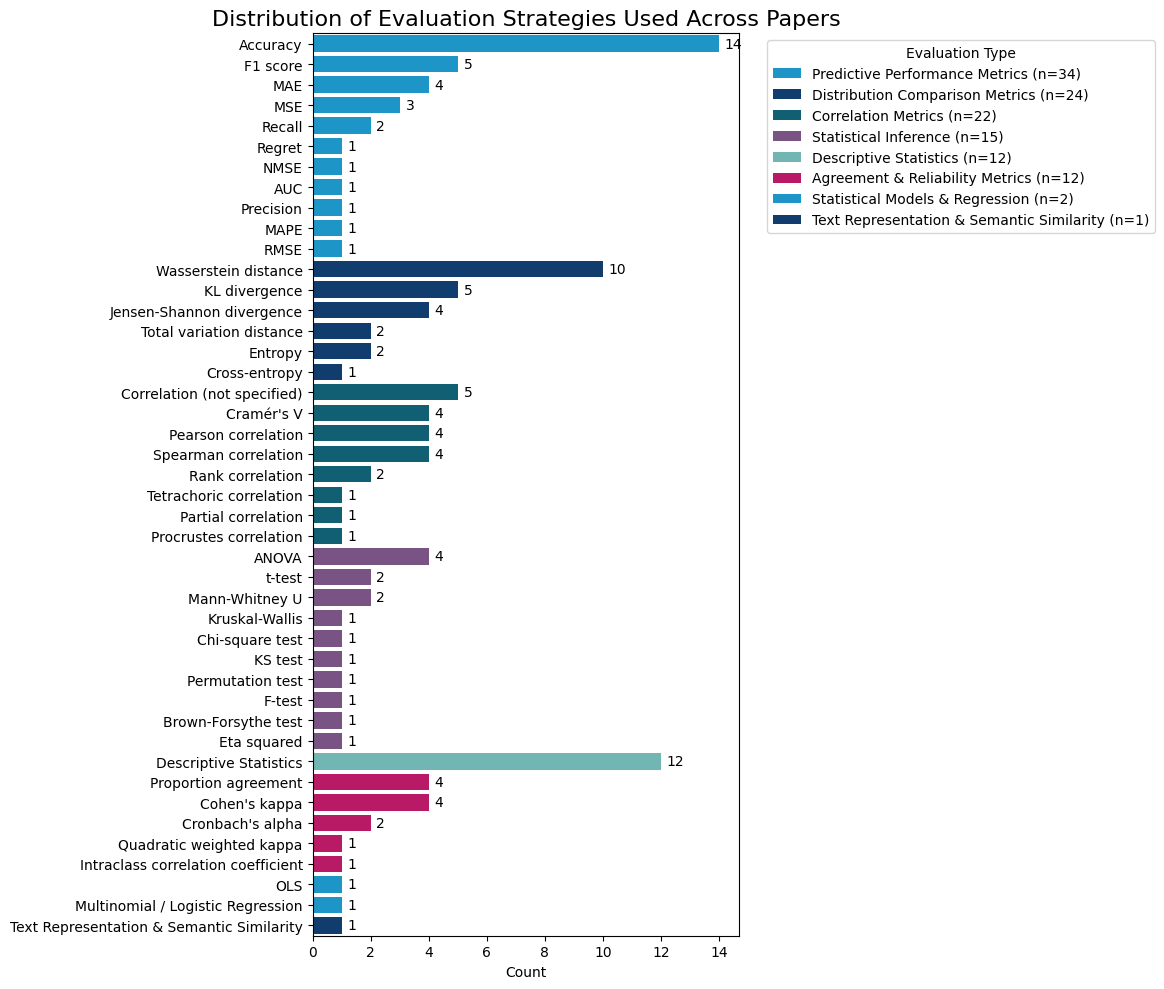

In [68]:
# Plot Type 1: 

category_totals = metric_counts.groupby('Category', observed=True)['Count'].sum().sort_values(ascending=False)
metric_counts['Category'] = pd.Categorical(metric_counts['Category'], categories=category_totals.index, ordered=True)
metric_counts = metric_counts.sort_values(['Category', 'Count'], ascending=[True, False])

plt.figure(figsize=(12, 10))
sns.barplot(x='Count', y='Metric', hue='Category', data=metric_counts, dodge=False, palette=FIX_COLORS)
plt.xlabel('Count')
plt.ylabel('')
plt.title('Distribution of Evaluation Strategies Used Across Papers', fontsize=16)
for i, v in enumerate(metric_counts['Count']):
    plt.text(v + 0.2, i, str(v), color='black', va='center')
handles, labels = plt.gca().get_legend_handles_labels()
new_labels = [f"{label} (n={int(category_totals[label])})" for label in labels]
plt.legend(handles, new_labels, title='Evaluation Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

# save_figure("Distribution_of_Evaluation_Strategies")
plt.show()

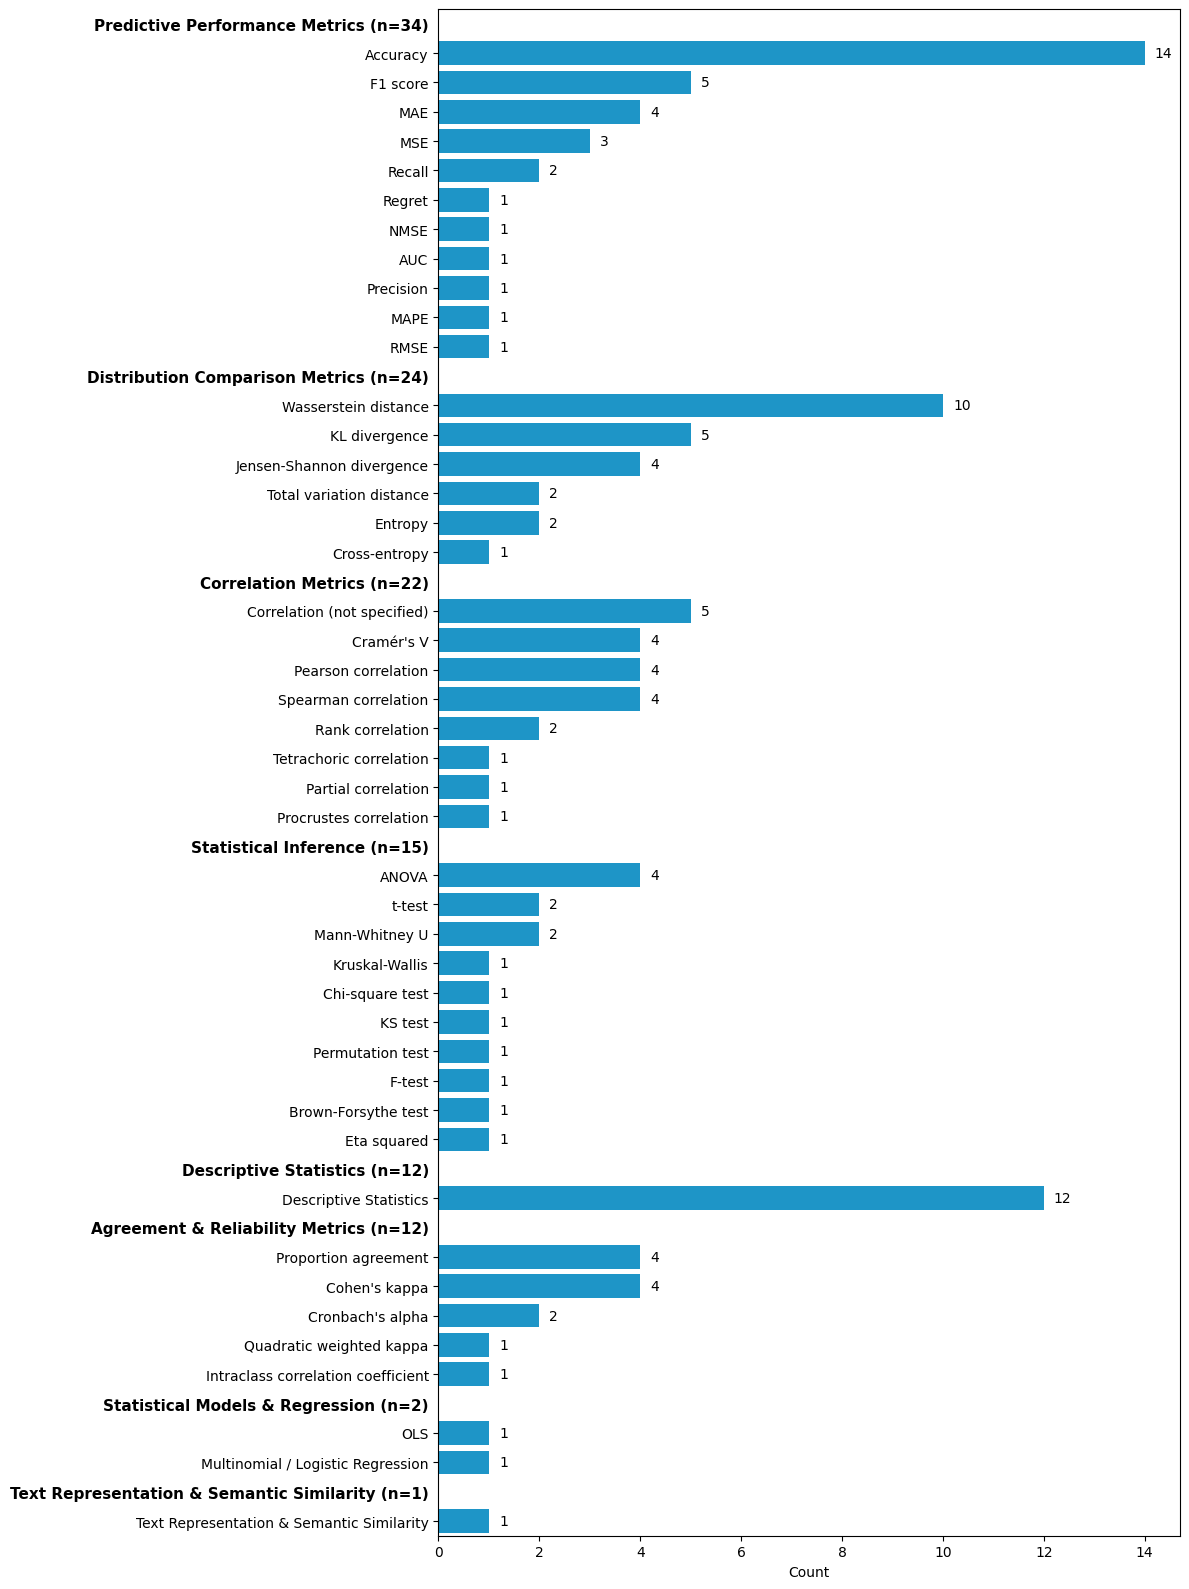

In [69]:
# Plot Type 2: 
category_totals = metric_counts.groupby('Category', observed=True)['Count'].sum().sort_values(ascending=False)
metric_counts['Category'] = pd.Categorical(metric_counts['Category'], categories=category_totals.index, ordered=True)
metric_counts = metric_counts.sort_values(['Category', 'Count'], ascending=[True, False]).reset_index(drop=True)

# Build dataframe with spacer rows, using the category name itself as the label
rows = []
categories_in_order = metric_counts['Category'].cat.categories
spacer_row_labels = set()  # track which Metric labels are spacer/header rows

for i, cat in enumerate(categories_in_order):
    label = f"{cat} (n={int(category_totals[cat])})"
    rows.append({'Metric': label, 'Count': np.nan, 'Category': cat})
    spacer_row_labels.add(label)
    cat_rows = metric_counts[metric_counts['Category'] == cat]
    rows.extend(cat_rows.to_dict('records'))

plot_df = pd.DataFrame(rows).reset_index(drop=True)
plot_df['_row'] = range(len(plot_df))

fig, ax = plt.subplots(figsize=(12, 16))

sns.barplot(x='Count', y='Metric', data=plot_df, ax=ax, order=plot_df['Metric'])

ax.set_xlabel('Count')
ax.set_ylabel('')
# ax.set_title('Distribution of Evaluation Strategies Used Across Papers', fontsize=16)

for i, v in enumerate(plot_df['Count']):
    if pd.notna(v):
        ax.text(v + 0.2, i, str(int(v)), color='black', va='center')

# --- Bold the header rows' tick labels and remove their tick marks ---
for tick, ticklabel in zip(ax.yaxis.get_major_ticks(), ax.get_yticklabels()):
    if ticklabel.get_text() in spacer_row_labels:
        ticklabel.set_fontweight('bold')
        ticklabel.set_fontsize(11)
        tick.tick1line.set_visible(False)  # remove the little tick mark
        tick.tick2line.set_visible(False)

ax.set_ylim(len(plot_df) - 0.5, -0.5)

plt.tight_layout()
save_figure("Distribution_of_Evaluation_Strategies")
plt.show()

## Validity of LLMs as Human Proxies

In [70]:
# Analyze the distribution of the "Results: LLM Capabilities" column

# Define a dictionary
patterns_capabilities = {
    "LLM as Valid Substitutes": r"(?i)\bthey\s+work\b",
    "LLM as Invalid Substitutes": r"(?i)\bthey\s+don['’]t\s+work\b",
    "LLM as Conditional Valid Substitutes": r"(?i)\bsometimes\s+they\s+work\b",
}

# Create binary columns
df_capabilities = df_extraction_table[['Title', 'Results: LLM Capabilities', 'Year']].copy()
for capability, pattern in patterns_capabilities.items():
    df_capabilities[capability] = df_capabilities['Results: LLM Capabilities'].apply(
        lambda x: int(bool(re.search(pattern, str(x).lower())))
    )
df_capabilities.loc[df_capabilities['LLM as Conditional Valid Substitutes'] == 1, 
                    'LLM as Valid Substitutes'] = 0

# Count the number of papers that fall into each category
capability_counts = df_capabilities[patterns_capabilities.keys()].sum().reset_index()
capability_counts.columns = ['LLM Capability Result', 'Count']
capability_counts = capability_counts.sort_values('Count', ascending=False).reset_index(drop=True)

# Count the number of papers that fall into each category in each year (so three columns: Year, LLM capabilitiy, Count)
capability_counts_year = df_capabilities.groupby('Year').agg({capability: 'sum' for capability in patterns_capabilities.keys()}).reset_index()
capability_counts_year = capability_counts_year.melt(id_vars='Year', var_name='LLM Capability Result', value_name='Count')
capability_counts_year = capability_counts_year.sort_values(['Year', 'LLM Capability Result'], ascending=[True, False]).reset_index(drop=True)

# Pivot data
capability_counts_year_pivot = capability_counts_year.pivot_table(
    index='Year',
    columns='LLM Capability Result',
    values='Count',
    aggfunc='sum',
    fill_value=0
)

print(capability_counts)
capability_counts_year_pivot

                  LLM Capability Result  Count
0  LLM as Conditional Valid Substitutes     34
1            LLM as Invalid Substitutes     13
2              LLM as Valid Substitutes      8


LLM Capability Result,LLM as Conditional Valid Substitutes,LLM as Invalid Substitutes,LLM as Valid Substitutes
Year,,,
2023,4,2,1
2024,14,3,2
2025,16,8,5


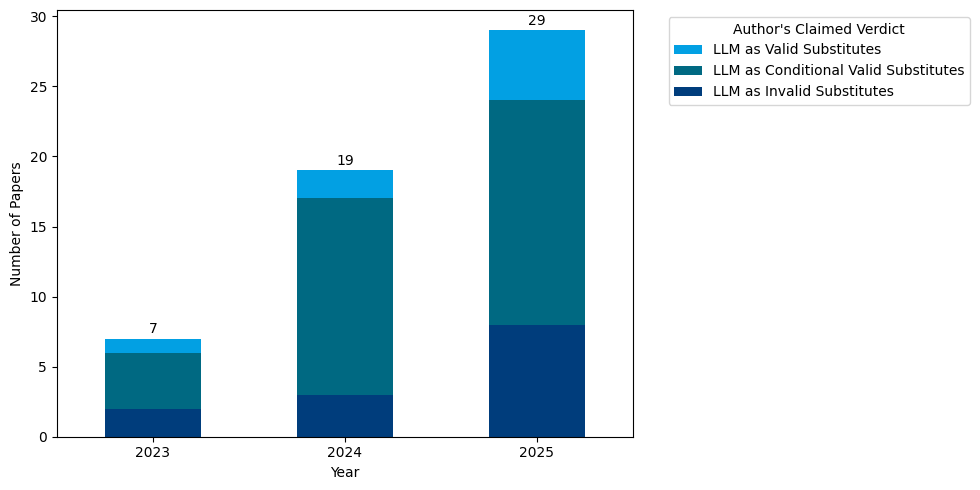

In [71]:
# Plot
stacked_data = capability_counts_year_pivot[patterns_capabilities.keys()]

# Keep each category's current color (taken from the active color cycle in the original order)
cycle_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
color_map = dict(zip(stacked_data.columns, cycle_colors))

# Stack order: 
stack_order = ["LLM as Invalid Substitutes", 
               "LLM as Conditional Valid Substitutes", 
               "LLM as Valid Substitutes"]
stacked_data = stacked_data[stack_order]

ax = stacked_data.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 5),
    color=[color_map[c] for c in stack_order]
)

plt.xlabel('Year')
plt.ylabel('Number of Papers')
# plt.title('Authors\' Assessment of LLM Capabilities', fontsize=16)

# Reverse legend so it matches the visual top-to-bottom order of the bars
handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles[::-1], labels[::-1],
    title="Author's Claimed Verdict",
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

# Add total count labels above each stacked bar
totals = stacked_data.sum(axis=1)

for i, total in enumerate(totals):
    ax.text(
        i,
        total + 0.2,
        int(total),
        ha='center',
        va='bottom'
    )
plt.xticks(rotation=0)
plt.tight_layout()
save_figure("Validity_of_LLMs_as_Human_Proxies")
plt.show()

# Master Coded Table 
**As replication Supplementary Material**

Combine the final coding result from each subsection above into a single per-paper table for the supplementary material.

In [100]:
# Helper: collapse a set of binary indicator columns into one "; "-joined label column per row
def consolidate_labels(df, category_cols, sep="; "):
    sub = df[category_cols]
    joined = sub.apply(lambda row: sep.join(row.index[row == 1].tolist()), axis=1)
    return joined.replace("", pd.NA)

# Base table: one row per paper
master_table = df_extraction_table[['Title', 'Authors', 'Year', 'DOI link']].copy()


In [101]:
# Distribution of Survey Datasets
master_table = master_table.merge(
    df_surveydataset[['Title', 'Survey_Category']],
    on='Title', how='left'
)

# Data Contamination
master_table = master_table.merge(
    df_contamination[['Title', 'Contamination_Category']],
    on='Title', how='left'
)

In [102]:
# Distribution of Survey Population
population_cols = list(patterns_Population.keys())
pop_labels = df_population[['Title']].copy()
pop_labels['Survey_Population_Countries'] = consolidate_labels(df_population, population_cols)
master_table = master_table.merge(pop_labels, on='Title', how='left')

# Distribution of Variables Predicted
variable_cols = list(patterns_VariablesPredicted.keys())
var_labels = df_variables[['Title']].copy()
var_labels['Predicted_Variable_Categories'] = consolidate_labels(df_variables, variable_cols)
master_table = master_table.merge(var_labels, on='Title', how='left')


In [103]:
# Distributions of LLMs: Model Family
model_family_cols = list(model_rules.keys())
model_labels = df_models[['Title']].copy()
model_labels['LLM_Model_Families'] = consolidate_labels(df_models, model_family_cols)
master_table = master_table.merge(model_labels, on='Title', how='left')

# Model Source (Open / Closed / Both) - mutually exclusive indicator columns
source_cols = ['Only Open Source', 'Only Closed Source', 'Both Open and Closed Source']
source_labels = df_models_source[['Title']].copy()
source_labels['LLM_Model_Source'] = consolidate_labels(df_models_source, source_cols)
master_table = master_table.merge(source_labels, on='Title', how='left')

# Specific OpenAI models (only populated for papers using the OpenAI GPT family)
openai_cols = list(patterns_openai.keys())
openai_labels = df_gpt_models[['Title']].copy()
openai_labels['OpenAI_Specific_Models'] = consolidate_labels(df_gpt_models, openai_cols)
master_table = master_table.merge(openai_labels, on='Title', how='left')

# Specific Llama models (only populated for papers using the Llama family)
llama_cols = list(patterns_llama.keys())
llama_labels = df_llama_models[['Title']].copy()
llama_labels['Llama_Specific_Models'] = consolidate_labels(df_llama_models, llama_cols)
master_table = master_table.merge(llama_labels, on='Title', how='left')


In [104]:
# Persona-Creation Strategies: General Approach
method_cols = list(patterns_methods.keys())
method_labels = df_methods[['Title']].copy()
method_labels['Persona_Construction_Strategy'] = consolidate_labels(df_methods, method_cols)
master_table = master_table.merge(method_labels, on='Title', how='left')

# Fine-Tuning Input (only populated for model-level fine-tuning papers)
trainingdata_cols = list(patterns_trainingdata.keys())
trainingdata_labels = df_trainingdata[['Title']].copy()
trainingdata_labels['FineTuning_Training_Data_Types'] = consolidate_labels(df_trainingdata, trainingdata_cols)
master_table = master_table.merge(trainingdata_labels, on='Title', how='left')

# Prompting Input (use the sub-category name only, for readability)
promptinput_cols = [c for c in df_promptinput.columns if c not in ['Title', 'LLM Training / Prompting Input']]
promptinput_labels = df_promptinput[['Title']].copy()
raw_prompt_labels = consolidate_labels(df_promptinput, promptinput_cols)
promptinput_labels['Prompting_Input_Types'] = raw_prompt_labels.apply(
    lambda x: "; ".join(part.split(" - ", 1)[-1].replace("\n", " ").strip() for part in x.split("; "))
    if pd.notna(x) else x
)
master_table = master_table.merge(promptinput_labels, on='Title', how='left')

# Demographic Input Types
demographic_cols = list(patterns_Demographic.keys())
demographic_labels = df_demographics[['Title']].copy()
demographic_labels['Demographic_Input_Types'] = consolidate_labels(df_demographics, demographic_cols)
master_table = master_table.merge(demographic_labels, on='Title', how='left')


In [105]:
# Training Data & Training Specifications (raw fields, plus extracted size numbers)
master_table = master_table.merge(
    df_extraction_table[['Title', 'Training Dataset', 'Training Dataset Size']],
    on='Title', how='left'
)
master_table = master_table.rename(columns={
    'Training Dataset': 'Training_Dataset',
    'Training Dataset Size': 'Training_Dataset_Size',
})
master_table['Training_Dataset_Size_Numbers'] = (
    master_table['Training_Dataset_Size'].astype('string')
    .str.findall(r"\d[\d,]*\.?\d*")
    .apply(lambda xs: "; ".join(xs) if isinstance(xs, list) and len(xs) > 0 else pd.NA)
)


In [106]:
# Evaluation Strategy: Alignment Level + Evaluation Metrics (already consolidated in df_metrics)
eval_labels = df_metrics[['Title', 'Alignment', 'All Metrics: Category', 'All Metrics']].copy()
eval_labels = eval_labels.rename(columns={
    'Alignment': 'Alignment_Level',
    'All Metrics: Category': 'Evaluation_Metric_Categories',
    'All Metrics': 'Evaluation_Metrics',
})
master_table = master_table.merge(eval_labels, on='Title', how='left')

# Evaluation metrics: 
metrics_labels = df_metrics[['Title', 'All Metrics: Category', 'All Metrics']].copy()
metrics_labels = metrics_labels.rename(columns={
    'All Metrics: Category': 'Evaluation_Metric_Categories',
    'All Metrics': 'Evaluation_Metrics',
})
master_table = master_table.merge(metrics_labels, on='Title', how='left')

# Relational Alignment (Yes/No) comes from df_alignment, not df_metrics
relational_labels = df_alignment[['Title', 'Relational Alignment']].copy()
relational_labels['Relational Alignment'] = relational_labels['Relational Alignment'].map({1: 'Yes', 0: 'No'})
relational_labels = relational_labels.rename(columns={'Relational Alignment': 'Relational_Alignment'})
master_table = master_table.merge(relational_labels, on='Title', how='left')


In [107]:
# Distribution of LLM Capabilities
capability_cols = list(patterns_capabilities.keys())
capability_labels = df_capabilities[['Title']].copy()
capability_labels['LLM_Capability_Result'] = consolidate_labels(df_capabilities, capability_cols)

In [108]:
master_table = master_table.merge(capability_labels, on='Title', how='left')
master_table.to_csv(base / "data/extraction/Master_Coded_Table.csv", index=False)

# Build Crosstab Table

In [99]:
# Load in Master Table
master_table = pd.read_csv(base / "data/extraction/Master_Coded_Table.csv")

In [113]:
# Setup
CSV_PATH = "SLR_-_Master_Coded_Table.csv"     # input file
OUT_PATH = "stacked_crosstab_by_verdict.csv"  # output file
 
VERDICT_COL = "LLM_Capability_Result"

VERDICT_ORDER = ["LLM as Valid Substitutes", 
                 "LLM as Conditional Valid Substitutes", 
                 "LLM as Invalid Substitutes"]
 
# >>> Select whichever "study design" columns you want here <<<
STUDY_DESIGN_COLUMNS = ['Survey_Category',
 'Contamination_Category',
 'Survey_Population_Countries',
 'Predicted_Variable_Categories',
 'LLM_Model_Families',
 'LLM_Model_Source',
 'Persona_Construction_Strategy',
 'Prompting_Input_Types',
 'Alignment_Level',
 'Relational_Alignment']
 
# Columns that hold multiple ";"-separated values per study (leave as-is;
# the script auto-detects this too, but you can force it here if needed)
MULTI_VALUE_DELIM = ";"
SHOW_PERCENT = True # Format for each cell: "n (pct%)" (row %) or just "n"


df = master_table.copy()
 
def explode_column(df, col, delim=MULTI_VALUE_DELIM):
    """Split a ';'-delimited column into one row per value, keeping the verdict."""
    sub = df[[col, VERDICT_COL]].copy()
    sub[col] = sub[col].astype(str).str.split(delim)
    sub = sub.explode(col)
    sub[col] = sub[col].str.strip()
    sub = sub[sub[col].ne("") & sub[col].notna() & sub[col].ne("nan")]
    return sub.reset_index(drop=True)
 
 
def fmt_cell(n, total, show_percent=SHOW_PERCENT):
    if not show_percent:
        return str(int(n))
    pct = (n / total * 100) if total else 0
    return f"{int(n)} ({round(pct)}%)"


In [115]:
# Create a stacked crosstab for each study design column
blocks = []
 
for col in STUDY_DESIGN_COLUMNS:
    exploded = explode_column(df, col)
 
    ct = pd.crosstab(exploded[col], exploded[VERDICT_COL])
    # ensure all verdict columns exist, in the desired order
    for v in VERDICT_ORDER:
        if v not in ct.columns:
            ct[v] = 0
    ct = ct[VERDICT_ORDER]
 
    row_totals = ct.sum(axis=1)
 
    block = pd.DataFrame(index=ct.index)
    block.insert(0, "Study Design Choice", col)
    block.insert(1, "Category", ct.index)
    for v in VERDICT_ORDER:
        block[v] = [fmt_cell(ct.loc[cat, v], row_totals[cat]) for cat in ct.index]
    block["Total (row n)"] = row_totals.values
 
    # sort categories by descending total n (comment out to sort alphabetically instead)
    block = block.sort_values("Total (row n)", ascending=False).reset_index(drop=True)
 
    blocks.append(block)
 
stacked = pd.concat(blocks, ignore_index=True)
stacked.to_csv(base / "results/tables/Crosstab_Table_byVerdict.csv", index=False)
stacked

,Study Design Choice,Category,LLM as Valid Substitutes,LLM as Conditional Valid Substitutes,LLM as Invalid Substitutes,Total (row n)
0,Survey_Category,Established Surveys,5 (16%),19 (61%),7 (23%),31
1,Survey_Category,Other questionnaires,3 (14%),13 (62%),5 (24%),21
2,Survey_Category,Prolific custom questionnaires,0 (0%),2 (67%),1 (33%),3
3,Contamination_Category,A: Not addressed,5 (12%),25 (62%),10 (25%),40
4,Contamination_Category,C: Temporal exclusion (postdates training cutoff),2 (33%),3 (50%),1 (17%),6
...,...,...,...,...,...,...
69,Alignment_Level,Aggregated-distributional level Alignment,5 (13%),23 (61%),10 (26%),38
70,Alignment_Level,Individual-level Alignment,2 (22%),7 (78%),0 (0%),9
71,Alignment_Level,Both individual and distributional alignment L...,1 (12%),4 (50%),3 (38%),8
72,Relational_Alignment,No,7 (15%),31 (65%),10 (21%),48


### Plot

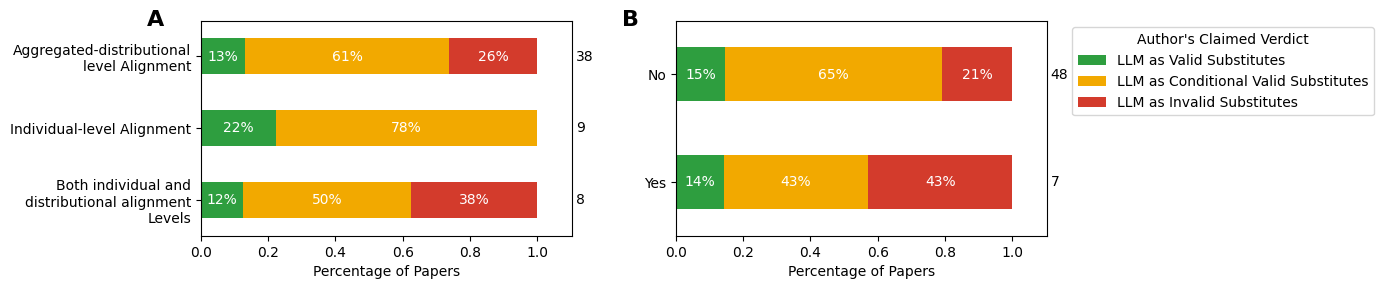

In [ ]:
# Plot Verdict against Alignment Level and Relational Alignment (horizontal bar percentage)
verdict_colors = {
    "LLM as Valid Substitutes": "#2E9E3F",
    "LLM as Conditional Valid Substitutes": "#F2A900",
    "LLM as Invalid Substitutes": "#D33B2C",
}
stack_order = list(verdict_colors.keys())

panels = [("Alignment_Level", "Alignment Level"),
          ("Relational_Alignment", "Relational Alignment")]

fig, axes = plt.subplots(1, 2, figsize=(14, 3), sharex=True)

for ax, letter, (col, title) in zip(axes, "AB", panels):
    # one row per (study, category), splitting ";"-separated values
    sub = df[[col, VERDICT_COL]].dropna().copy()
    sub[col] = sub[col].astype(str).str.split(";")
    sub = sub.explode(col)
    sub[col] = sub[col].str.strip()
    sub = sub[sub[col].ne("") & sub[col].ne("nan")]

    ct = pd.crosstab(sub[col], sub[VERDICT_COL]).reindex(columns=stack_order, fill_value=0)
    ct = ct.loc[ct.sum(axis=1).sort_values(ascending=False).index]
    totals = ct.sum(axis=1)
    ct = ct.div(totals, axis=0)  # convert to percentages

    ct.plot(kind="barh", stacked=True, color=[verdict_colors[v] for v in stack_order],
            ax=ax, legend=False)
    ax.invert_yaxis()  # largest category on top

    # count inside each segment (white), total at the end of each bar (black)
    for container in ax.containers:
        ax.bar_label(container, labels=[f"{w:.0%}" if w > 0 else "" for w in container.datavalues],
                     label_type="center", color="white")
    for i, total in enumerate(totals):
        ax.text(1.01, i, str(total), color="black", va="center", transform=ax.get_yaxis_transform())

    ax.set_yticks(range(len(ct)), labels=[textwrap.fill(c, 30) for c in ct.index])
    ax.set_xlabel("Percentage of Papers")
    ax.set_ylabel("")
    # ax.set_title(title, fontsize=14)
    ax.text(-0.1, 1.05, letter, transform=ax.transAxes, fontsize=16, fontweight="bold", va="top", ha="right")

axes[0].set_xlim(right=axes[0].get_xlim()[1] * 1.05)  # room for the total labels
axes[1].legend(title="Author's Claimed Verdict", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
save_figure("plot_verdictBy_Alignment_combined")
plt.show()
